# Hauptexperiment II: Längeneinhaltung und längenadjustierte Faktenretention

## Eingaben und Ausgaben

Nach der einmaligen Vorbereitung mit `python 05_analyze.py --prepare` genügt **Run All**.
Die folgende Zelle zeigt Daten, Vorgängertabellen und neue Ausgaben. `DATA_DIR` und
`OUTPUT_DIR` dürfen auf eigene absolute Verzeichnisse zeigen. `TABLES` liest standardmäßig
die vorbereiteten historischen Tabellen; für selbst neu erzeugte Vorgängertabellen
kann hier `OUTPUT_DIR / "tables"` stehen. Eingaben und neue Ausgaben bleiben getrennt.


In [1]:
from pathlib import Path
from faktenretention.paths import PROJECT_ROOT
from faktenretention.notebook_context import setup_notebook
from faktenretention.io import relative_path, sha

# Hier können eigene absolute Daten- und Ausgabeverzeichnisse stehen.
DATA_DIR = PROJECT_ROOT / "data/prepared"
OUTPUT_DIR = PROJECT_ROOT / "results/notebooks"
# Historische Vorgängertabellen; für eigene Neuberechnungen OUTPUT_DIR / "tables" einsetzen.
TABLES = DATA_DIR / "tables"
setup_notebook(DATA_DIR, OUTPUT_DIR)
OUT = OUTPUT_DIR / "tables/04_laenge_und_adjustierte_retention"
FIG = OUTPUT_DIR / "figures/04_laenge_und_adjustierte_retention"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
print("Eingaben:", DATA_DIR / "qa")
print("Vorgängertabellen:", TABLES)
print("Neue Tabellen:", OUT)
print("Neue Grafiken:", FIG)


Eingaben: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/qa
Vorgängertabellen: /home/edgar/Faktenretention_Notebook_Refactor/data/prepared/tables
Neue Tabellen: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/tables/04_laenge_und_adjustierte_retention
Neue Grafiken: /home/edgar/Faktenretention_Notebook_Refactor/results/notebooks/figures/04_laenge_und_adjustierte_retention


**Kapitel 4.3 · F3 und H2 · aktueller Ergebnisstand aktuell_20260930.**

Untersucht werden die Einhaltung der Wortfenster, die gemeinsame Betrachtung von
Längenabweichung und beobachteter QA-Retention sowie die Änderung der Rangfolgen
durch die eingefrorene Sekundärkennzahl. Die Verläufe und vier QA-Kontraste aus
Kapitel 4.2 werden hier nicht wiederholt.

**Lesereihenfolge:** Definitionen und Integrität → Kurzüberblick → 4.3.1 Wortvorgaben
→ 4.3.2 Retention und Länge/H2 → Sensitivität → Anhang und Ergebnistext.

Das Notebook berechnet die Ergebnisse aus gespeicherten Texten und Einzelurteilen
neu und prüft sie gegen die Exporte aus 4.2. Es benötigt keine Modellaufrufe oder
API-Zugänge. Die beiden Hauptabbildungen verwenden jeweils ein **2×2-Raster**.

## 1. Definitionen, Version und Reproduzierbarkeit

Eine Analysezeile ist **Artikel × Methode × Zielstufe**: 100 × 6 × 4 = 2.400.
Der aktuelle Stand verbindet vier ursprüngliche Verfahren mit den neuen Plain-
und Few-Shot-CoT-Ketten vom 30. September 2026. Alte und neue Ergebnisse derselben
Methode werden nicht gepoolt. Lead-k bleibt als deterministische Baseline enthalten.

Wörter werden mit **re.findall(r"\b\w+\b", text)** gezählt; dies sind Regex-Wörter,
keine Modelltokens. Die inklusive Fenstergrenze und die eingefrorene Formel werden
gegen die gespeicherten Generierungszustände geprüft.

| Ziel T | Untergrenze U | Obergrenze O |
|---:|---:|---:|
| 500 | 475 | 525 |
| 300 | 285 | 315 |
| 150 | 142 | 158 |
| 75 | 71 | 79 |

- under_words = max(U − W, 0); over_words = max(W − O, 0).
- window_hit = U ≤ W ≤ O; D = (under_words + over_words) / T.
- R_obs = K / V; R_zero = K / 20; R_adj = R_zero / (1 + D).

**D = 0,10** bedeutet eine Abweichung um 10 % der Zielwortzahl jenseits der nächsten
zulässigen Grenze. Eine leere Ausgabe hat W = 0 und bleibt zugleich als Fehler markiert.

**Präzisierung des Freeze:** Innerhalb des Fensters gilt R_adj = R_zero.
R_adj = R_obs gilt dort nur bei V = 20 (oder zufällig gleichem Wert, etwa K = 0).
Der feste QA-Nenner und der Längenabschlag sind daher getrennte Komponenten.
R_adj wird zuerst pro Artikel berechnet und anschließend gemittelt.

**Unsicherheit:** 10.000 Artikelbootstrap-Ziehungen, Seed 32, punktweise
95-%-Perzentilintervalle. Derselbe gezogene Artikel bringt alle Methoden und Stufen
mit. Die Kennzahl und H2 werden deskriptiv ausgewertet; kein nachträglicher Hypothesentest.

In [2]:
from pathlib import Path
from collections import Counter
from fractions import Fraction
from itertools import combinations
import gzip, hashlib, importlib.util, importlib.metadata, json, math, platform, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

BASE = DATA_DIR
VERSION = "aktuell_20260930"
DATA = DATA_DIR / "qa"
SOURCE42 = TABLES / "03_qa_retention"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
SEED, B, N_FACTS = 32, 10_000, 20
from faktenretention.protocol import METHODS
from faktenretention.protocol import STAGES
from faktenretention.protocol import WINDOWS
from faktenretention.protocol import LABELS as LABELS
COLORS = dict(zip(METHODS, ["#777777", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]))
MARKERS = dict(zip(METHODS, ["o", "s", "^", "D", "v", "P"]))
CELL = ["article_id", "method", "stage_target_words"]
KEY = CELL + ["canonical_fact_id"]
from faktenretention.text_rules import count_words
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 30)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

from faktenretention.io import read_table as read

def as_bool(series):
    assert series.astype(str).str.lower().isin(["true", "false"]).all()
    return series.astype(str).str.lower().eq("true")

def fmt(value, digits=2):
    return f"{value:.{digits}f}".replace(".", ",")

def export(frame, name):
    frame.to_csv(OUT / f"{name}.csv", index=False)

def savefig(fig, name):
    for ext in ["png", "svg", "pdf"]:
        fig.savefig(FIG / f"{name}.{ext}", bbox_inches="tight")
    plt.show()
    plt.close(fig)

software = {p: importlib.metadata.version(p) for p in ["numpy", "pandas", "matplotlib", "nbformat", "nbclient"]}
display(Markdown(f"**Datenstand:** {VERSION} · **Bootstrap:** {B:,} Ziehungen, Seed {SEED}."))


**Datenstand:** aktuell_20260930 · **Bootstrap:** 10,000 Ziehungen, Seed 32.

## 2. Quellen und Integritätsprüfungen

Die Rohdaten und der Scorer liegen als eingefrorene Snapshots vor. Die Checks prüfen
SHA-256, vollständige Schlüssel, Datenversionen, ausgewählte Ausgaben, Wortzähler,
Fensterstatus, rekursive Eingaben und QA-Zuordnung. Die drei Rohretentionswerte
Artikelwert, Gruppenmittelwert und Bootstrap-Intervall werden gegen Kapitel 4.2
geprüft. Übereinstimmung der Fließkommawerte wird mit absoluter Toleranz 10⁻¹²
geprüft; Zähler und Schlüssel müssen exakt identisch sein.

In [3]:
manifest = json.loads((DATA / "source_manifest.json").read_text())
source_hashes = []
for entry in manifest["files"]:
    # Verify only the selected run, shared inputs and code; no pooling of versions.
    if not entry["file"].startswith((VERSION + "/", "shared/", "code/")):
        continue
    path = DATA / entry["file"]
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == entry["sha256"], path
    if path.suffix == ".gz":
        assert hashlib.sha256(gzip.decompress(path.read_bytes())).hexdigest() == entry["original_sha256"], path
    source_hashes.append({"file": relative_path(path, BASE), "sha256": digest, "role": "frozen_input"})
dependencies42 = ["retention_artikelebene.csv", "retention_mittelwerte_95ci.csv",
                  "qa_labels_reproduziert.csv.gz", "generation_status_und_rekursive_eingaben.csv", "execution_manifest.json"]
for name in dependencies42:
    path = SOURCE42 / name
    assert path.is_file(), f"Kapitel-4.2-Export fehlt: {path}"
    source_hashes.append({"file": relative_path(path, BASE), "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
                          "role": "chapter_4_2_crosscheck"})
manifest42 = json.loads((SOURCE42 / "execution_manifest.json").read_text())
assert manifest42["version"] == VERSION and manifest42["seed"] == SEED and manifest42["bootstrap_samples"] == B
merge_manifest = json.loads((DATA / VERSION / "provenienz/result_merge_manifest.json").read_text())
assert merge_manifest["retained_historical_rows"] == 400
assert merge_manifest["replaced_plain_rows"] == merge_manifest["replaced_few_shot_rows"] == 100
assert merge_manifest["historical_plain_or_few_shot_rows_in_new_table"] == 0
freeze = json.loads((DATA / "original_frozen/provenienz/frozen_protocol.json").read_text())
assert freeze["length_adjusted_retention_formula"] == "retention_all_missing_zero / (1 + word_window_violation_rate)"
freeze_entry = next(e for e in manifest["files"] if e["file"] == "original_frozen/provenienz/frozen_protocol.json")
assert hashlib.sha256((DATA / freeze_entry["file"]).read_bytes()).hexdigest() == freeze_entry["sha256"]
source_hashes.append({"file": "qa/original_frozen/provenienz/frozen_protocol.json",
                      "sha256": hashlib.sha256((DATA / "original_frozen/provenienz/frozen_protocol.json").read_bytes()).hexdigest(),
                      "role": "formula_only_no_original_results"})
export(pd.DataFrame(source_hashes), "quellen_sha256")
summaries = read(DATA / VERSION / "summaries.csv.gz")
facts = read(DATA / "shared/canonical_facts.csv.gz")
assert len(summaries) == 600 and not summaries.duplicated(["article_id", "method"]).any()
assert len(facts) == 2_000 and facts.canonical_fact_id.is_unique
IDS = sorted(facts.article_id.unique().tolist())
assert len(IDS) == 100 and facts.groupby("article_id").size().eq(N_FACTS).all()
assert set(summaries[["article_id", "method"]].itertuples(index=False, name=None)) == set((a,m) for a in IDS for m in METHODS)
expected_phase = {m: "plain_fewshot_rerun_20260930" if m in ["plain", "few_shot_cot"] else "final_100_frozen_temperature_0" for m in METHODS}
assert summaries.collection_phase.eq(summaries.method.map(expected_phase)).all()
display(summaries.groupby(["method", "collection_phase"]).size().rename("Artikel").reset_index())


,method,collection_phase,Artikel
0,auto_cot,final_100_frozen_temperature_0,100
1,automate_cot,final_100_frozen_temperature_0,100
2,few_shot_cot,plain_fewshot_rerun_20260930,100
3,lead_k,final_100_frozen_temperature_0,100
4,plain,plain_fewshot_rerun_20260930,100
5,zero_shot_cot,final_100_frozen_temperature_0,100


In [4]:
from faktenretention.text_rules import count_words
records = []
with gzip.open(DATA / VERSION / "generation_states.jsonl.gz", "rt") as stream:
    states = [json.loads(line) for line in stream]
assert len(states) == 600
assert len({(rec["article_id"], rec["method"]) for rec in states}) == 600
lookup = summaries.set_index(["article_id", "method"])
for rec in states:
    state = rec["state"]
    row = lookup.loc[(rec["article_id"], rec["method"])]
    assert state["complete"] and state["method"] == rec["method"]
    assert state["source_sha256"] == row.article_sha256
    assert hashlib.sha256(row.article.encode()).hexdigest() == row.article_sha256
    assert [s["target_words"] for s in state["stages"]] == STAGES
    previous = row.article
    chain_failure = False
    for stage in state["stages"]:
        target = stage["target_words"]
        selected = stage["selected"]
        text = selected["response"]
        assert text == row[f"summary_{target}"] and stage["input_text"] == previous
        W = count_words(text)
        assert W == int(row[f"summary_{target}_word_count"]) == selected["response_word_count"]
        assert count_words(previous) == stage["input_word_count"]
        U, O = WINDOWS[target]
        under, over = max(U-W, 0), max(W-O, 0)
        hit = U <= W <= O
        D = (under+over) / target
        empty = not text.strip()
        assert selected["word_window_success"] == hit
        # The replacement Plain/Few-shot states do not store D; derive it from their checked W.
        stored_D_available = "word_window_violation_rate" in selected
        if stored_D_available:
            assert selected["word_window_violation_words"] == under+over
            assert np.isclose(selected["word_window_violation_rate"], D, rtol=0, atol=1e-12)
        assert selected.get("empty_output", empty) == empty
        assert str(row[f"summary_{target}_final_window_success"]).lower() == str(hit).lower()
        assert str(row[f"summary_{target}_complete_sentence_success"]).lower() == str(selected["ends_with_complete_sentence"]).lower()
        chain_failure = chain_failure or empty
        records.append(dict(article_id=rec["article_id"], method=rec["method"], stage_target_words=target,
            collection_phase=row.collection_phase, summary=text, summary_sha256=hashlib.sha256(text.encode()).hexdigest(),
            W=W, U=U, O=O, under_words=under, over_words=over, violation_words=under+over,
            D=D, under_D=under/target, over_D=over/target, window_hit=hit, stored_D_available=stored_D_available,
            window_status="under" if under else "over" if over else "within", empty_output=empty,
            empty_input=not previous.strip(), chain_failure=chain_failure, complete=state["complete"],
            complete_sentence=selected["ends_with_complete_sentence"], attempts=len(stage["attempts"]),
            done_reason=selected.get("done_reason", "deterministic"), source_state_file=rec["source_file"]))
        previous = text
lengths = pd.DataFrame(records)
expected_cells = {(a,m,t) for a in IDS for m in METHODS for t in STAGES}
assert len(lengths) == 2_400 and not lengths.duplicated(CELL).any()
assert set(lengths[CELL].itertuples(index=False, name=None)) == expected_cells
assert lengths.attempts.eq(1).all()
audit42 = read(SOURCE42 / "generation_status_und_rekursive_eingaben.csv")
audit_check = lengths.merge(audit42[CELL + ["empty_output", "empty_input", "chain_failure"]], on=CELL, validate="one_to_one", suffixes=("", "_42"))
for flag in ["empty_output", "empty_input", "chain_failure"]:
    assert audit_check[flag].eq(as_bool(audit_check[flag + "_42"])).all(), flag
failed_ids = sorted(lengths.loc[lengths.empty_output, "article_id"].unique().tolist())
assert len(failed_ids) == 2 and lengths.empty_output.sum() == 2
display(lengths.loc[lengths.chain_failure, CELL + ["W", "window_status", "empty_output", "empty_input", "chain_failure", "done_reason"]])
assert lengths.stored_D_available.sum() == 1_600
display(Markdown(f"**Alle 2.400 Wortzähler und Fensterstatus stimmen mit den gespeicherten Zuständen überein.** "
                 "Bei 1.600 Positionen wurde auch D direkt gegen den gespeicherten Wert geprüft; "
                 "die neuen Plain-/Few-shot-Zustände speichern D nicht separat. Dort wird D aus dem nachgezählten W abgeleitet. "
                 f"Leere Ausgaben in Artikeln {failed_ids}; {int(lengths.chain_failure.sum())} Stufenpositionen in betroffenen Ketten."))


,article_id,method,stage_target_words,W,window_status,empty_output,empty_input,chain_failure,done_reason
631,40,zero_shot_cot,75,0,under,True,False,True,length
1446,91,zero_shot_cot,150,0,under,True,False,True,length
1447,91,zero_shot_cot,75,33,under,False,True,True,stop


**Alle 2.400 Wortzähler und Fensterstatus stimmen mit den gespeicherten Zuständen überein.** Bei 1.600 Positionen wurde auch D direkt gegen den gespeicherten Wert geprüft; die neuen Plain-/Few-shot-Zustände speichern D nicht separat. Dort wird D aus dem nachgezählten W abgeleitet. Leere Ausgaben in Artikeln [40, 91]; 3 Stufenpositionen in betroffenen Ketten.

In [5]:
qa = read(DATA / VERSION / "answers.csv.gz").rename(columns={"summary_prompt_variant": "method"})
assert len(qa) == 48_000 and not qa.duplicated(KEY).any()
expected_qa = {(a,m,t,f) for a,fs in facts.groupby("article_id") for m in METHODS for t in STAGES for f in fs.canonical_fact_id}
assert set(qa[KEY].itertuples(index=False, name=None)) == expected_qa
qa = qa.merge(facts[["article_id", "canonical_fact_id", "question", "reference_answer"]],
              on=["article_id", "canonical_fact_id"], validate="many_to_one", suffixes=("", "_fact"))
for field in ["question", "reference_answer"]:
    assert qa[field].eq(qa[field + "_fact"]).all()
qa = qa.merge(lengths[CELL + ["summary", "empty_output", "chain_failure"]], on=CELL, validate="many_to_one")
from faktenretention import scoring as scorer
qa["analysis_eligible"] = qa.error.astype(str).eq("")
qa["grounded"] = [scorer.support_is_grounded(s,a,e) for s,a,e in zip(qa.summary,qa.answer,qa.support)]
assert qa.loc[qa.analysis_eligible, "grounded"].all()
qa["retained"] = [scorer.retained(ref,ans) if valid else False for ref,ans,valid in zip(qa.reference_answer,qa.answer,qa.analysis_eligible)]
qa["lost"] = qa.analysis_eligible & qa.answer.str.upper().eq("NOT_FOUND")
qa["label"] = np.select([~qa.analysis_eligible, qa.retained, qa.lost],
                        ["technical_missing", "retained", "lost"], default="reference_discordant")
labels42 = read(SOURCE42 / "qa_labels_reproduziert.csv.gz")
labels_check = qa[KEY + ["label", "analysis_eligible"]].merge(labels42[KEY + ["label", "analysis_eligible"]],
                on=KEY, validate="one_to_one", suffixes=("", "_42"))
assert len(labels_check) == 48_000 and labels_check.label.eq(labels_check.label_42).all()
assert labels_check.analysis_eligible.eq(as_bool(labels_check.analysis_eligible_42)).all()
assert qa.loc[qa.empty_output, "answer"].eq("NOT_FOUND").all()
aggregated = qa.groupby(CELL).agg(n_total=("canonical_fact_id", "size"), V=("analysis_eligible", "sum"), K=("retained", "sum")).reset_index()
assert len(aggregated) == 2_400 and aggregated.n_total.eq(N_FACTS).all()
assert aggregated.V.gt(0).all() and aggregated.K.le(aggregated.V).all()
article = lengths.merge(aggregated, on=CELL, validate="one_to_one")
article["n_missing"] = N_FACTS - article.V
article["R_obs"] = article.K / article.V
article["R_zero"] = article.K / N_FACTS
article["R_adj"] = article.R_zero / (1 + article.D)
article["qa_denominator_gap"] = article.R_obs - article.R_zero
article["length_penalty"] = article.R_zero - article.R_adj
assert np.allclose(article.R_obs - article.R_adj, article.qa_denominator_gap + article.length_penalty, rtol=0, atol=1e-15)
assert article.R_adj.le(article.R_zero + 1e-15).all() and article.R_zero.le(article.R_obs + 1e-15).all()
assert article.loc[article.window_hit, "R_adj"].eq(article.loc[article.window_hit, "R_zero"]).all()
assert article.loc[article.empty_output, ["W", "K", "R_obs", "R_zero", "R_adj"]].eq(0).all().all()
previous = read(SOURCE42 / "retention_artikelebene.csv")
cross = article.merge(previous[CELL + ["n_retained", "n_valid", "retention_observed", "retention_lower"]], on=CELL, validate="one_to_one")
assert len(cross) == 2_400 and cross.K.eq(cross.n_retained).all() and cross.V.eq(cross.n_valid).all()
assert np.allclose(cross.R_obs, cross.retention_observed, rtol=0, atol=1e-12)
assert np.allclose(cross.R_zero, cross.retention_lower, rtol=0, atol=1e-12)
export(article.drop(columns="summary"), "artikelwerte_laenge_retention")
integrity = pd.DataFrame({"Einheit": ["Artikel", "Artikel × Methode", "Analysezeilen", "QA-Urteile", "Gültige QA-Urteile", "Leere Ausgaben"],
                         "Anzahl": [len(IDS), len(summaries), len(article), len(qa), int(qa.analysis_eligible.sum()), int(article.empty_output.sum())]})
display(integrity)
export(integrity, "integritaet_und_nenner")


,Einheit,Anzahl
0,Artikel,100
1,Artikel × Methode,600
2,Analysezeilen,2400
3,QA-Urteile,48000
4,Gültige QA-Urteile,47804
5,Leere Ausgaben,2


## 3. Schätzungen und Rangfolgen

Alle Gruppen umfassen dieselben Artikel. Eine gemeinsame Ziehungsmatrix pro
Artikelmenge erhält die Paarung für sämtliche Methoden, Stufen und Kennzahlen.
Die 98-Artikel-Sensitivität verwendet ihre eigene Matrix mit Seed 32.

Die Rangfolgen beruhen auf **ungerundeten Mittelwerten**. Die Punktschätzer werden
zusätzlich als exakte rationale Mittelwerte berechnet, damit mathematisch gleiche
Werte keine künstlichen Ränge durch Fließkommarundung erhalten. Bei echten Gleichständen
gilt Wettbewerbsrang (z. B. 1, 2, 2, 4). Eine Gleichrangigkeit beim festen QA-Nenner ist
in der 98-Artikel-Sensitivität relevant. Bootstrap-Ränge von R_obs und R_zero verwenden
ganzzahlig skalierte Zähler; die nichtlineare adjustierte Kennzahl verwendet float64.

In [6]:
index_cache = {}
bootstrap_cache = {}
exact_cache = {}

def indices(ids):
    key = tuple(ids)
    if key not in index_cache:
        index_cache[key] = np.random.default_rng(SEED).integers(0, len(ids), size=(B, len(ids)))
    return index_cache[key]

def exact_value(row, metric):
    if metric == "D":
        return Fraction(int(row.violation_words), int(row.stage_target_words))
    if metric == "window_hit":
        return Fraction(int(row.window_hit), 1)
    if metric == "R_obs":
        return Fraction(int(row.K), int(row.V))
    if metric == "R_zero":
        return Fraction(int(row.K), N_FACTS)
    if metric == "R_adj":
        return Fraction(int(row.K) * int(row.stage_target_words), N_FACTS * int(row.stage_target_words + row.violation_words))
    if metric == "qa_denominator_gap":
        return exact_value(row, "R_obs") - exact_value(row, "R_zero")
    if metric == "length_penalty":
        return exact_value(row, "R_zero") - exact_value(row, "R_adj")
    raise KeyError(metric)

def estimate_group(group, metric):
    group = group.sort_values("article_id")
    ids = tuple(group.article_id)
    key = (ids, group.method.iloc[0], int(group.stage_target_words.iloc[0]), metric)
    if key not in bootstrap_cache:
        point = sum((exact_value(row, metric) for row in group.itertuples()), Fraction(0)) / len(group)
        ix = indices(ids)
        if metric in ["R_obs", "R_zero", "D", "window_hit"]:
            fractions = [exact_value(row, metric) for row in group.itertuples()]
            denominator = math.lcm(*(v.denominator for v in fractions))
            numerator = np.array([v.numerator * (denominator // v.denominator) for v in fractions], dtype=np.int64)
            draws = numerator[ix].sum(axis=1) / (denominator * len(group))
        else:
            draws = group[metric].to_numpy(dtype=float)[ix].mean(axis=1)
        bootstrap_cache[key] = draws
        exact_cache[key] = point
    low, high = np.quantile(bootstrap_cache[key], [.025, .975])
    return float(exact_cache[key]), float(low), float(high), bootstrap_cache[key], exact_cache[key]


In [7]:
def tables_for(frame, scenario):
    rows = []
    for stage in STAGES:
        for method in METHODS:
            group = frame[(frame.method == method) & (frame.stage_target_words == stage)]
            assert set(group.article_id) == set(frame.article_id.unique())
            row = dict(scenario=scenario, method=method, stage_target_words=stage, n_articles=len(group),
                n_under=int(group.window_status.eq("under").sum()), n_within=int(group.window_hit.sum()),
                n_over=int(group.window_status.eq("over").sum()), n_empty=int(group.empty_output.sum()),
                n_empty_input=int(group.empty_input.sum()), n_chain_failure=int(group.chain_failure.sum()),
                W_mean=float(group.W.mean()), W_median=float(group.W.median()), W_p10=float(group.W.quantile(.1)),
                W_p90=float(group.W.quantile(.9)), W_min=int(group.W.min()), W_max=int(group.W.max()),
                D_median=float(group.D.median()), D_p90=float(group.D.quantile(.9)), D_max=float(group.D.max()),
                under_words_mean=float(group.under_words.mean()), over_words_mean=float(group.over_words.mean()),
                under_D_mean=float(group.under_D.mean()), over_D_mean=float(group.over_D.mean()),
                n_missing_qa=int(group.n_missing.sum()), n_complete_sentences=int(group.complete_sentence.sum()))
            assert row["n_under"] + row["n_within"] + row["n_over"] == len(group)
            for status in ["under", "within", "over"]:
                row[f"share_{status}"] = row[f"n_{status}"] / len(group)
            for metric in ["D", "window_hit", "R_obs", "R_zero", "R_adj", "qa_denominator_gap", "length_penalty"]:
                mean,low,high,draws,exact = estimate_group(group, metric)
                row.update({f"{metric}_mean": mean, f"{metric}_ci_low": low, f"{metric}_ci_high": high})
                if metric.startswith("R_"):
                    row[f"{metric}_exact_mean"] = str(exact)
            rows.append(row)
    table = pd.DataFrame(rows)
    for metric in ["R_obs", "R_zero", "R_adj"]:
        table[f"rank_{metric}"] = 0
        for stage in STAGES:
            selection = table.stage_target_words.eq(stage)
            exacts = [Fraction(s) for s in table.loc[selection, f"{metric}_exact_mean"]]
            table.loc[selection, f"rank_{metric}"] = [1 + sum(other > value for other in exacts) for value in exacts]
    table["rank_changed_H2"] = table.rank_R_obs.ne(table.rank_R_adj)
    table["rank_changed_denominator"] = table.rank_R_obs.ne(table.rank_R_zero)
    table["rank_changed_length"] = table.rank_R_zero.ne(table.rank_R_adj)
    table["dominated_point_estimate"] = False
    table["dominated_by"] = ""
    for idx,row in table.iterrows():
        others = table[(table.stage_target_words == row.stage_target_words) & (table.method != row.method)]
        dominating = others[(others.R_obs_mean >= row.R_obs_mean) & (others.D_mean <= row.D_mean)
                            & ((others.R_obs_mean > row.R_obs_mean) | (others.D_mean < row.D_mean))]
        table.loc[idx,"dominated_point_estimate"] = not dominating.empty
        table.loc[idx,"dominated_by"] = ";".join(dominating.method)
    return table

main = tables_for(article, "main_100")
reference_means = read(SOURCE42 / "retention_mittelwerte_95ci.csv")
means_check = main.merge(reference_means[["method", "stage_target_words", "mean", "ci_low", "ci_high"]],
                         on=["method", "stage_target_words"], validate="one_to_one")
crosscheck_records = []
for new,old in [("R_obs_mean", "mean"), ("R_obs_ci_low", "ci_low"), ("R_obs_ci_high", "ci_high")]:
    delta = (means_check[new] - means_check[old]).abs()
    assert delta.max() <= 1e-12, new
    crosscheck_records.append({"new_column": new, "chapter_4_2_column": old, "max_absolute_difference": float(delta.max()), "passed": True})
export(pd.DataFrame(crosscheck_records), "abgleich_kapitel_4_2")
export(main, "vollstaendige_24_gruppen_main_100")
display(pd.DataFrame(crosscheck_records))


,new_column,chapter_4_2_column,max_absolute_difference,passed
0,R_obs_mean,mean,1.110223e-16,True
1,R_obs_ci_low,ci_low,1.110223e-16,True
2,R_obs_ci_high,ci_high,2.220446e-16,True


In [8]:
def pairwise_for(frame, scenario):
    rows = []
    for stage in STAGES:
        for first,second in combinations(METHODS, 2):
            left = frame[(frame.method == first) & (frame.stage_target_words == stage)].sort_values("article_id")
            right = frame[(frame.method == second) & (frame.stage_target_words == stage)].sort_values("article_id")
            assert left.article_id.tolist() == right.article_id.tolist()
            row = dict(scenario=scenario, stage_target_words=stage, first=first, second=second, n_articles=len(left))
            for metric in ["R_obs", "R_zero", "R_adj", "D"]:
                lm,ll,lh,ld,le = estimate_group(left, metric)
                rm,rl,rh,rd,rex = estimate_group(right, metric)
                delta = ld - rd
                low,high = np.quantile(delta, [.025, .975])
                multiplier = 1 if metric == "D" else 100
                row.update({f"delta_{metric}": float(le-rex)*multiplier,
                            f"delta_{metric}_ci_low": float(low)*multiplier, f"delta_{metric}_ci_high": float(high)*multiplier})
                if metric != "D":
                    difference = le - rex
                    row[f"order_{metric}"] = 1 if difference > 0 else -1 if difference < 0 else 0
                if metric == "R_adj":
                    row["bootstrap_share_first_higher_R_adj"] = float((delta > 0).mean())
                    row["bootstrap_share_tied_R_adj"] = float((delta == 0).mean())
            row["order_changed_H2"] = row["order_R_obs"] != row["order_R_adj"]
            row["order_changed_denominator"] = row["order_R_obs"] != row["order_R_zero"]
            row["order_changed_length"] = row["order_R_zero"] != row["order_R_adj"]
            rows.append(row)
    return pd.DataFrame(rows)

def stability_for(frame, table, scenario):
    probabilities, orders = [], []
    for stage in STAGES:
        group_table = table[table.stage_target_words.eq(stage)].set_index("method").loc[METHODS]
        for metric in ["R_obs", "R_zero", "R_adj"]:
            draws = np.column_stack([estimate_group(frame[(frame.method==m)&(frame.stage_target_words==stage)], metric)[3] for m in METHODS])
            ranks = 1 + (draws[:,None,:] > draws[:,:,None]).sum(axis=2)
            observed = group_table[f"rank_{metric}"].to_numpy(dtype=int)
            counts = Counter(map(tuple, ranks.tolist()))
            modal,count = counts.most_common(1)[0]
            orders.append(dict(scenario=scenario,stage_target_words=stage,metric=metric,
                method_order=";".join(METHODS), observed_rank_vector=";".join(map(str,observed)),
                observed_order_frequency=float(np.all(ranks==observed,axis=1).mean()),
                modal_rank_vector=";".join(map(str,modal)), modal_order_frequency=count/B))
            for j,method in enumerate(METHODS):
                for rank in range(1,7):
                    probabilities.append(dict(scenario=scenario,stage_target_words=stage,metric=metric,method=method,
                        rank=rank,bootstrap_frequency=float((ranks[:,j]==rank).mean())))
    return pd.DataFrame(probabilities), pd.DataFrame(orders)

pairs = pairwise_for(article, "main_100")
rank_probabilities, rank_orders = stability_for(article, main, "main_100")
export(pairs, "gepaarte_differenzen_main_100")
export(rank_probabilities, "bootstrap_ranghaeufigkeiten_main_100")
export(rank_orders, "bootstrap_vollstaendige_rangfolgen_main_100")
changes = pairs[pairs.order_changed_H2]
assert not main.rank_changed_denominator.any(), "Nennerbedingte Rangänderung im Hauptpanel prüfen."
summary_text = (f"**Kurzüberblick:** Lead-k trifft alle vier Wortfenster bei allen 100 Artikeln. "
    f"Unter den generativen Verfahren liegen die Trefferquoten je Stufe zwischen "
    f"{int(main[main.method.ne('lead_k')].n_within.min())} und {int(main[main.method.ne('lead_k')].n_within.max())} %. "
    f"Die Rangfolge R_obs → R_adj ändert sich auf {main.groupby('stage_target_words').rank_changed_H2.any().sum()} von vier Stufen "
    f"({int(main.rank_changed_H2.sum())}/24 Rangpositionen). "
    "Im 100-Artikel-Hauptpanel erzeugt der feste QA-Nenner keine Rangänderung; die Wechsel entstehen erst durch den Längenabschlag. "
    "Knappe adjustierte Unterschiede werden mit gepaarten Intervallen und Bootstrap-Ranghäufigkeiten ausgewiesen.")
display(Markdown(summary_text))


**Kurzüberblick:** Lead-k trifft alle vier Wortfenster bei allen 100 Artikeln. Unter den generativen Verfahren liegen die Trefferquoten je Stufe zwischen 0 und 33 %. Die Rangfolge R_obs → R_adj ändert sich auf 3 von vier Stufen (11/24 Rangpositionen). Im 100-Artikel-Hauptpanel erzeugt der feste QA-Nenner keine Rangänderung; die Wechsel entstehen erst durch den Längenabschlag. Knappe adjustierte Unterschiede werden mit gepaarten Intervallen und Bootstrap-Ranghäufigkeiten ausgewiesen.

## 4.3.1 Einhaltung der Wortvorgaben

Die erste Hauptabbildung zeigt je Methode und Zielstufe die Anzahl der Artikel
**unter**, **innerhalb** und **über** dem inklusiven Wortfenster. Die Balkensumme ist
immer 100. Die Farben und Schraffuren kodieren den Fensterstatus, nicht das Verfahren.
Trefferquoten allein bilden die Größe der Abweichungen nicht ab; Mittelwert und
Verteilung von D stehen deshalb in der anschließenden Tabelle.

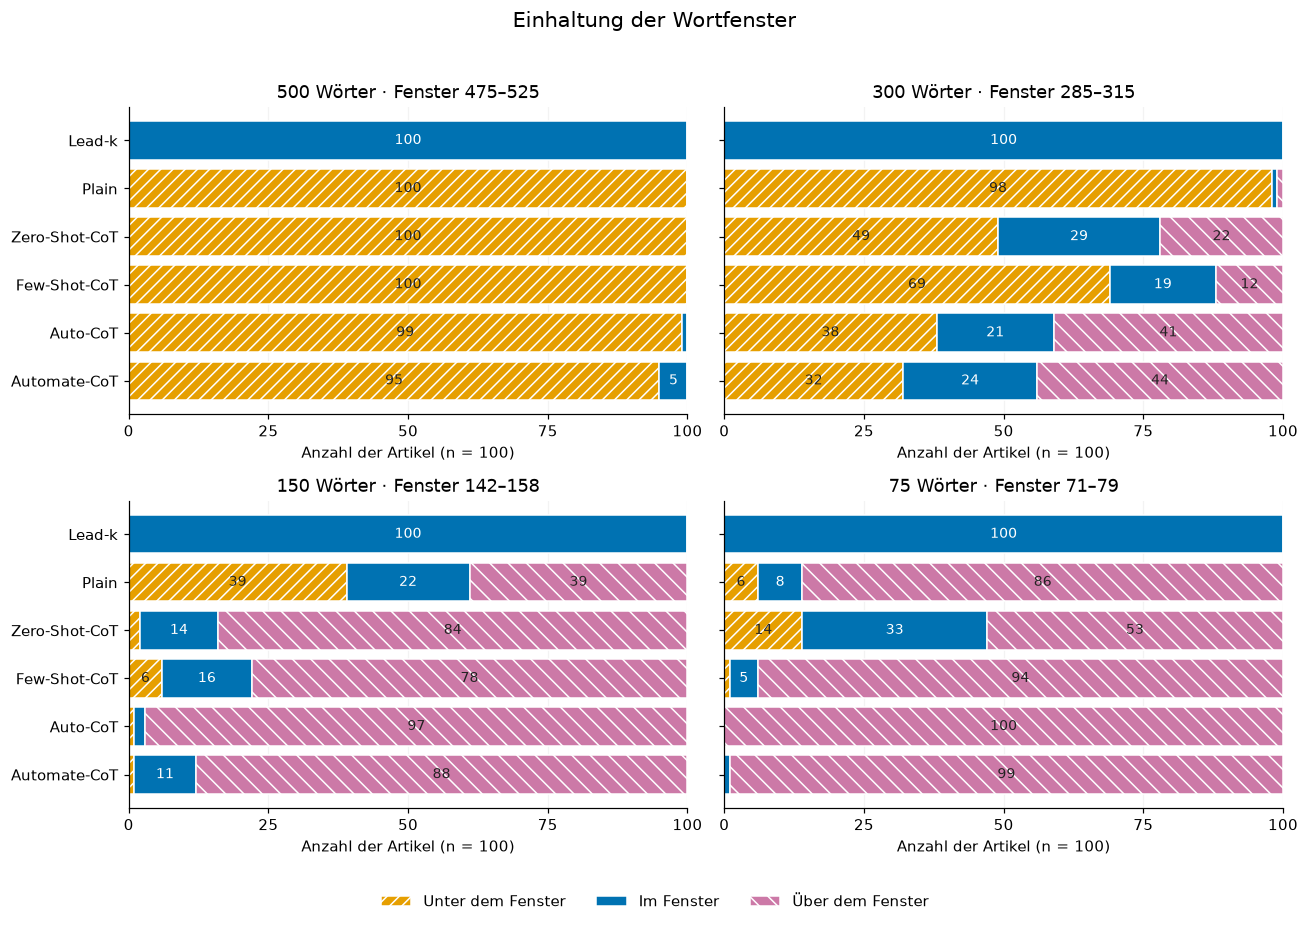

**Abbildung 4.3-1.** Unter-/Fenster-/Überzahlen bei 100 gepaarten Artikeln je Verfahren und Stufe. Leere Ausgaben zählen als Unterschreitung. Kleine Segmente ohne Innenbeschriftung sind in der Tabelle vollständig ausgewiesen.

In [9]:
STATUS_COLORS = {"under": "#E69F00", "within": "#0072B2", "over": "#CC79A7"}
STATUS_LABELS = {"under": "Unter dem Fenster", "within": "Im Fenster", "over": "Über dem Fenster"}
HATCHES = {"under": "///", "within": "", "over": "\\\\"}
fig,axes = plt.subplots(2,2,figsize=(12,8.6),sharex=True,sharey=True)
y = np.arange(len(METHODS))
for ax,stage in zip(axes.flat,STAGES):
    sub = main[main.stage_target_words.eq(stage)].set_index("method").loc[METHODS]
    left = np.zeros(len(METHODS))
    for status in ["under", "within", "over"]:
        counts = sub[f"n_{status}"].to_numpy()
        ax.barh(y,counts,left=left,color=STATUS_COLORS[status],edgecolor="white",hatch=HATCHES[status],label=STATUS_LABELS[status])
        for i,n in enumerate(counts):
            if n >= 5:
                ax.text(left[i]+n/2,y[i],str(n),ha="center",va="center",fontsize=9,
                        color="white" if status=="within" else "#222222")
        left += counts
    assert np.array_equal(left,np.full(6,100))
    U,O = WINDOWS[stage]
    ax.set(title=f"{stage} Wörter · Fenster {U}–{O}",xlim=(0,100),xticks=[0,25,50,75,100],
           yticks=y,yticklabels=[LABELS[m] for m in METHODS],xlabel="Anzahl der Artikel (n = 100)")
    ax.tick_params(axis="x",labelbottom=True)
    ax.set_axisbelow(True)
    ax.grid(axis="x",alpha=.15)
axes[0,0].invert_yaxis()
handles,labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc="lower center",ncol=3,frameon=False,bbox_to_anchor=(.5,.015))
fig.suptitle("Einhaltung der Wortfenster",fontsize=14)
fig.tight_layout(rect=(0,.07,1,.96))
savefig(fig,"01_wortfenster_einhaltung")
display(Markdown("**Abbildung 4.3-1.** Unter-/Fenster-/Überzahlen bei 100 gepaarten Artikeln je Verfahren und Stufe. "
                 "Leere Ausgaben zählen als Unterschreitung. Kleine Segmente ohne Innenbeschriftung sind in der Tabelle vollständig ausgewiesen."))


In [10]:
length_columns = ["method", "stage_target_words", "n_articles", "n_under", "n_within", "n_over",
    "share_under", "share_within", "share_over", "W_mean", "W_median", "W_p10", "W_p90", "W_min", "W_max",
    "D_mean", "D_ci_low", "D_ci_high", "D_median", "D_p90", "D_max", "under_words_mean", "over_words_mean",
    "under_D_mean", "over_D_mean", "window_hit_ci_low", "window_hit_ci_high", "n_empty", "n_empty_input", "n_chain_failure"]
length_table = main[length_columns]
export(length_table,"laengeneinhaltung_24_gruppen")
presentation = main.assign(Verfahren=main.method.map(LABELS),
    **{"Unter / im / über": [f"{r.n_under} / {r.n_within} / {r.n_over}" for r in main.itertuples()],
       "D [95-%-Intervall]": [f"{fmt(r.D_mean,3)} [{fmt(r.D_ci_low,3)}; {fmt(r.D_ci_high,3)}]" for r in main.itertuples()]})
display(presentation[["Verfahren","stage_target_words","Unter / im / über","W_mean","W_median",
                      "D [95-%-Intervall]","D_median","D_p90","D_max","n_empty"]].round(3))


,Verfahren,stage_target_words,Unter / im / über,W_mean,W_median,D [95-%-Intervall],D_median,D_p90,D_max,n_empty
0,Lead-k,500,0 / 100 / 0,500.00,500.0,"0,000 [0,000; 0,000]",0.000,0.000,0.000,0
1,Plain,500,100 / 0 / 0,209.31,209.5,"0,531 [0,513; 0,549]",0.531,0.654,0.708,0
2,Zero-Shot-CoT,500,100 / 0 / 0,345.29,344.5,"0,259 [0,240; 0,279]",0.261,0.390,0.504,0
3,Few-Shot-CoT,500,100 / 0 / 0,305.53,306.0,"0,339 [0,322; 0,355]",0.338,0.433,0.572,0
4,Auto-CoT,500,99 / 1 / 0,349.70,348.5,"0,251 [0,230; 0,272]",0.253,0.384,0.522,0
5,Automate-CoT,500,95 / 5 / 0,392.70,390.5,"0,166 [0,149; 0,182]",0.169,0.271,0.428,0
6,Lead-k,300,0 / 100 / 0,300.00,300.0,"0,000 [0,000; 0,000]",0.000,0.000,0.000,0
7,Plain,300,98 / 1 / 1,175.75,169.0,"0,368 [0,342; 0,392]",0.387,0.515,0.577,0
8,Zero-Shot-CoT,300,49 / 29 / 22,285.67,287.0,"0,070 [0,055; 0,086]",0.037,0.207,0.317,0
9,Few-Shot-CoT,300,69 / 19 / 12,270.07,269.5,"0,082 [0,067; 0,099]",0.058,0.197,0.387,0


## 4.3.2 Faktenretention unter Berücksichtigung der Länge

Die zweite Hauptabbildung vergleicht **24 Gruppenmittelwerte**: sechs Verfahren
je Zielstufe, gleichgewichtete Mittelwerte über 100 Artikel. Höhere beobachtete
Retention und geringere Fensterabweichung sind die beiden Primärdimensionen.
Beide Achsen sind über die vier Panels identisch skaliert.

Diese Darstellung beschreibt Unterschiede zwischen Verfahren bei gleicher Zielstufe.
Sie belegt weder eine Kausalwirkung der Textlänge noch eine artikelweise Korrelation.
Schwarze Ringe markieren nach den Punktschätzern nichtdominierte Verfahren.
Dominanz bedeutet: Kein anderes Verfahren hat mindestens so hohe R_obs und
höchstens so große D mit einem strikt besseren Wert. Unsicherheit wird dabei
nicht berücksichtigt; die Markierung ist keine formale Überlegenheitsaussage.

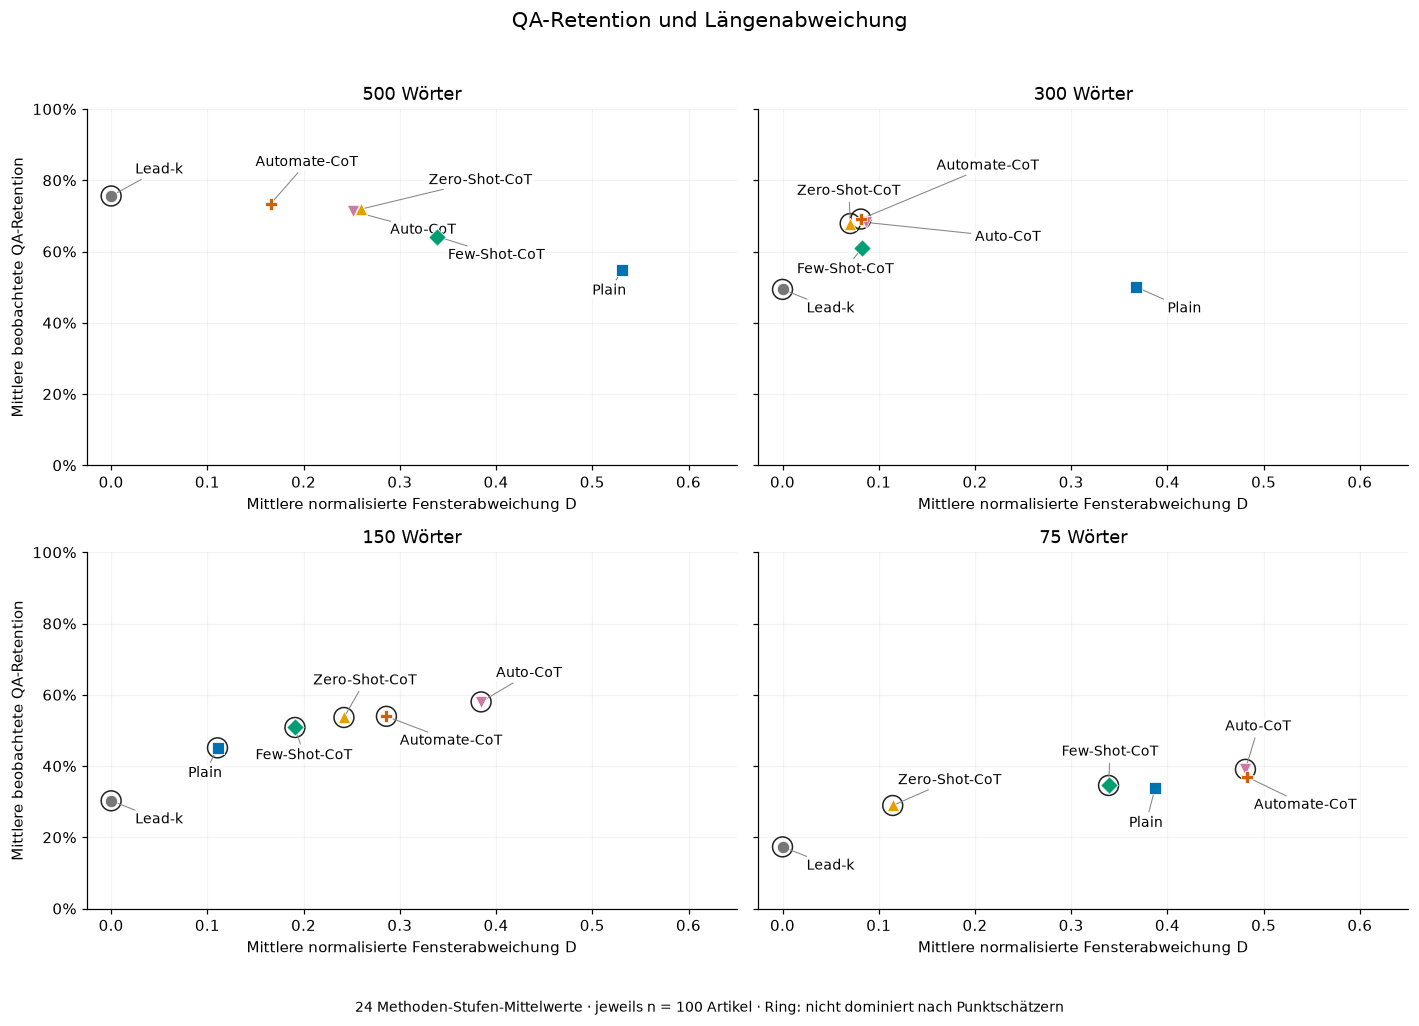

,Verfahren,stage_target_words,dominated_point_estimate,dominated_by
0,Lead-k,500,False,
1,Plain,500,True,lead_k;zero_shot_cot;few_shot_cot;auto_cot;aut...
2,Zero-Shot-CoT,500,True,lead_k;automate_cot
3,Few-Shot-CoT,500,True,lead_k;zero_shot_cot;auto_cot;automate_cot
4,Auto-CoT,500,True,lead_k;automate_cot
5,Automate-CoT,500,True,lead_k
6,Lead-k,300,False,
7,Plain,300,True,zero_shot_cot;few_shot_cot;auto_cot;automate_cot
8,Zero-Shot-CoT,300,False,
9,Few-Shot-CoT,300,True,zero_shot_cot;automate_cot


**Abbildung 4.3-2.** Methodenmittelwerte der beiden getrennten Primärdimensionen. Keine Regression und keine Kausalaussage; die Intervalle der Gruppenmittelwerte stehen in den CSV-Tabellen.

In [11]:
# Fixed annotation positions keep the labels of the nearby method means readable.
label_positions = {
    500: [(0.025,83),(.50,49),(.33,80),(.35,59),(.29,66),(.15,85)],
    300: [(0.025,44),(.40,44),(.015,77),(.015,55),(.20,64),(.16,84)],
    150: [(0.025,25),(.08,38),(.21,64),(.15,43),(.40,66),(.30,47)],
    75: [(0.025,12),(.36,24),(.12,36),(.29,44),(.46,51),(.49,29)]}
fig,axes = plt.subplots(2,2,figsize=(13,9.4),sharex=True,sharey=True)
for ax,stage in zip(axes.flat,STAGES):
    sub = main[main.stage_target_words.eq(stage)].set_index("method").loc[METHODS]
    for method,position in zip(METHODS,label_positions[stage]):
        row = sub.loc[method]
        x,y = row.D_mean,100*row.R_obs_mean
        if not row.dominated_point_estimate:
            ax.scatter(x,y,s=170,facecolors="none",edgecolors="#222222",linewidths=1,zorder=3)
        ax.scatter(x,y,s=65,marker=MARKERS[method],color=COLORS[method],edgecolors="white",linewidths=.5,zorder=4)
        ax.annotate(LABELS[method],xy=(x,y),xytext=position,textcoords="data",fontsize=9,
                    ha="left",va="center",arrowprops=dict(arrowstyle="-",color="#888888",lw=.7),
                    bbox=dict(boxstyle="square,pad=.08",fc="white",ec="none",alpha=.9))
    ax.set(title=f"{stage} Wörter",xlim=(-.025,.65),ylim=(0,100),xlabel="Mittlere normalisierte Fensterabweichung D")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100,decimals=0))
    ax.tick_params(axis="x",labelbottom=True)
    ax.grid(alpha=.15)
for ax in axes[:,0]:
    ax.set_ylabel("Mittlere beobachtete QA-Retention")
fig.suptitle("QA-Retention und Längenabweichung",fontsize=14)
fig.text(.5,.012,"24 Methoden-Stufen-Mittelwerte · jeweils n = 100 Artikel · Ring: nicht dominiert nach Punktschätzern",ha="center",fontsize=9)
fig.tight_layout(rect=(0,.05,1,.96))
savefig(fig,"02_retention_und_laengenabweichung")
export(main[["method","stage_target_words","R_obs_mean","D_mean","dominated_point_estimate","dominated_by"]],"pareto_punktschaetzer")
display(main.assign(Verfahren=main.method.map(LABELS))[["Verfahren","stage_target_words","dominated_point_estimate","dominated_by"]])
display(Markdown("**Abbildung 4.3-2.** Methodenmittelwerte der beiden getrennten Primärdimensionen. "
                 "Keine Regression und keine Kausalaussage; die Intervalle der Gruppenmittelwerte stehen in den CSV-Tabellen."))


### H2: Rangfolgen und Zerlegung der Abschläge

H2 vergleicht Rang nach mean(R_obs) mit Rang nach mean(R_adj); der Zwischenschritt
mean(R_zero) klärt, ob ein Wechsel schon durch den festen QA-Nenner entsteht.
Die Rangtabelle zeigt R_obs → R_adj. Ein Stern markiert einen tatsächlichen Wechsel.
Alle drei Ränge und die zwei Abschlagskomponenten stehen zusätzlich in der vollständigen Tabelle.

In [12]:
rank_display = pd.DataFrame(index=[LABELS[m] for m in METHODS],columns=STAGES)
for stage in STAGES:
    sub = main[main.stage_target_words.eq(stage)].set_index("method")
    for method in METHODS:
        row = sub.loc[method]
        rank_display.loc[LABELS[method],stage] = f"{row.rank_R_obs} → {row.rank_R_adj}" + (" *" if row.rank_changed_H2 else "")
rank_display.index.name = "Verfahren"
rank_display.columns = [f"{stage} Wörter" for stage in STAGES]
display(rank_display)
rank_display.to_csv(OUT/"h2_kompakte_rangtabelle.csv")
retention_columns = ["method","stage_target_words","n_articles","n_missing_qa",
    "R_obs_mean","R_obs_ci_low","R_obs_ci_high","R_zero_mean","R_zero_ci_low","R_zero_ci_high",
    "R_adj_mean","R_adj_ci_low","R_adj_ci_high","qa_denominator_gap_mean","length_penalty_mean",
    "rank_R_obs","rank_R_zero","rank_R_adj","rank_changed_H2","rank_changed_denominator","rank_changed_length"]
export(main[retention_columns],"retention_und_drei_rangfolgen_24_gruppen")
display(main[retention_columns].round(6))
display(Markdown("**Einheiten:** R-Werte und Abschlagskomponenten sind Anteile (0–1). "
                 "Mit 100 multipliziert ergeben sie Prozent beziehungsweise Prozentpunkte. "
                 "Im Hauptpanel bleibt die Rangfolge beim Schritt R_obs → R_zero unverändert."))


,500 Wörter,300 Wörter,150 Wörter,75 Wörter
Verfahren,,,,
Lead-k,1 → 1,6 → 5 *,6 → 6,6 → 6
Plain,6 → 6,5 → 6 *,5 → 5,4 → 5 *
Zero-Shot-CoT,3 → 3,3 → 2 *,3 → 1 *,5 → 2 *
Few-Shot-CoT,5 → 5,4 → 4,4 → 2 *,3 → 3
Auto-CoT,4 → 4,2 → 3 *,1 → 4 *,1 → 1
Automate-CoT,2 → 2,1 → 1,2 → 3 *,2 → 4 *


,method,stage_target_words,n_articles,n_missing_qa,R_obs_mean,R_obs_ci_low,R_obs_ci_high,R_zero_mean,R_zero_ci_low,R_zero_ci_high,...,R_adj_ci_low,R_adj_ci_high,qa_denominator_gap_mean,length_penalty_mean,rank_R_obs,rank_R_zero,rank_R_adj,rank_changed_H2,rank_changed_denominator,rank_changed_length
0,lead_k,500,100,5,0.755868,0.728315,0.782553,0.7540,0.726500,0.780500,...,0.726500,0.780500,0.001868,0.000000,1,1,1,False,False,False
1,plain,500,100,10,0.548915,0.515339,0.581148,0.5460,0.512500,0.578012,...,0.337219,0.385280,0.002915,0.184465,6,6,6,False,False,False
2,zero_shot_cot,500,100,7,0.718883,0.691412,0.745989,0.7165,0.689000,0.743500,...,0.549688,0.599583,0.002383,0.141818,3,3,3,False,False,False
3,few_shot_cot,500,100,16,0.641906,0.612117,0.670335,0.6370,0.607000,0.665500,...,0.454890,0.500418,0.004906,0.159092,5,5,5,False,False,False
4,auto_cot,500,100,12,0.713371,0.686136,0.739270,0.7095,0.682000,0.735500,...,0.548497,0.599263,0.003871,0.135581,4,4,4,False,False,False
5,automate_cot,500,100,11,0.733760,0.705974,0.760658,0.7300,0.702500,0.756500,...,0.604491,0.657778,0.003760,0.098885,2,2,2,False,False,False
6,lead_k,300,100,3,0.493684,0.466788,0.520395,0.4930,0.466000,0.520000,...,0.466000,0.520000,0.000684,0.000000,6,6,5,True,False,True
7,plain,300,100,10,0.500105,0.466526,0.532553,0.4975,0.464000,0.530000,...,0.344148,0.400709,0.002605,0.124588,5,5,6,True,False,True
8,zero_shot_cot,300,100,8,0.678535,0.650947,0.705457,0.6760,0.648000,0.703000,...,0.607880,0.664202,0.002535,0.039768,3,3,2,True,False,True
9,few_shot_cot,300,100,7,0.610427,0.580605,0.639743,0.6080,0.578500,0.637000,...,0.536484,0.592518,0.002427,0.043323,4,4,4,False,False,False


**Einheiten:** R-Werte und Abschlagskomponenten sind Anteile (0–1). Mit 100 multipliziert ergeben sie Prozent beziehungsweise Prozentpunkte. Im Hauptpanel bleibt die Rangfolge beim Schritt R_obs → R_zero unverändert.

In [13]:
display(Markdown("**Geänderte Paarreihenfolgen im Hauptpanel:** Die Differenz ist erste minus zweite Methode. "
                 "R-Differenzen und ihre punktweisen Intervalle sind in Prozentpunkten angegeben; D-Differenzen in D-Einheiten."))
display(changes[["stage_target_words","first","second","delta_R_obs","delta_R_zero","delta_R_adj",
                 "delta_R_adj_ci_low","delta_R_adj_ci_high","order_changed_denominator","order_changed_length"]].round(3))
display(rank_orders[rank_orders.metric.eq("R_adj")][["stage_target_words","observed_rank_vector",
             "observed_order_frequency","modal_rank_vector","modal_order_frequency"]].round(3))
display(Markdown("Die Rangvektoren folgen der festen Methodenreihenfolge Lead-k, Plain, Zero-Shot-CoT, "
                 "Few-Shot-CoT, Auto-CoT, Automate-CoT. Die Bootstrap-Häufigkeiten beschreiben Rangstabilität, "
                 "keine Wahrscheinlichkeit einer wahren Hypothese und keine p-Werte."))


**Geänderte Paarreihenfolgen im Hauptpanel:** Die Differenz ist erste minus zweite Methode. R-Differenzen und ihre punktweisen Intervalle sind in Prozentpunkten angegeben; D-Differenzen in D-Einheiten.

,stage_target_words,first,second,delta_R_obs,delta_R_zero,delta_R_adj,delta_R_adj_ci_low,delta_R_adj_ci_high,order_changed_denominator,order_changed_length
15,300,lead_k,plain,-0.642,-0.45,12.009,8.900,15.080,False,True
25,300,zero_shot_cot,auto_cot,-0.308,-0.20,0.858,-1.437,3.152,False,True
40,150,zero_shot_cot,auto_cot,-4.373,-4.10,1.525,-1.002,3.880,False,True
41,150,zero_shot_cot,automate_cot,-0.322,-0.15,1.178,-1.441,3.584,False,True
42,150,few_shot_cot,auto_cot,-7.177,-7.25,0.535,-1.552,2.662,False,True
43,150,few_shot_cot,automate_cot,-3.126,-3.30,0.188,-1.914,2.354,False,True
44,150,auto_cot,automate_cot,4.051,3.95,-0.346,-2.412,1.695,False,True
50,75,plain,zero_shot_cot,4.874,4.80,-1.613,-3.710,0.487,False,True
54,75,zero_shot_cot,few_shot_cot,-5.624,-5.50,0.212,-1.815,2.221,False,True
56,75,zero_shot_cot,automate_cot,-8.064,-8.00,0.895,-1.136,2.879,False,True


,stage_target_words,observed_rank_vector,observed_order_frequency,modal_rank_vector,modal_order_frequency
2,500,1;6;3;5;4;2,0.527,1;6;3;5;4;2,0.527
5,300,5;6;2;4;3;1,0.390,5;6;2;4;3;1,0.390
8,150,6;5;1;2;4;3,0.176,6;5;1;2;4;3,0.176
11,75,6;5;2;3;1;4,0.133,6;5;2;3;1;4,0.133


Die Rangvektoren folgen der festen Methodenreihenfolge Lead-k, Plain, Zero-Shot-CoT, Few-Shot-CoT, Auto-CoT, Automate-CoT. Die Bootstrap-Häufigkeiten beschreiben Rangstabilität, keine Wahrscheinlichkeit einer wahren Hypothese und keine p-Werte.

## 5. Sensitivität: dieselben 98 Artikel für alle Verfahren

Die beiden Artikel mit leeren Zero-Shot-Ausgaben werden **gemeinsam für alle Methoden
und Stufen** ausgeschlossen. Dadurch bleiben sämtliche Vergleiche gepaart.
Die Hauptanalyse enthält diese Fehler weiterhin. Die Sensitivität ändert zugleich die
Artikelpopulation und ist kein Ersatz für das 100-Artikel-Ergebnis.

In [14]:
sensitivity_article = article[~article.article_id.isin(failed_ids)].copy()
assert sensitivity_article.article_id.nunique() == 98 and len(sensitivity_article) == 98*6*4
assert not sensitivity_article.chain_failure.any()
sensitivity = tables_for(sensitivity_article,"without_empty_articles_98")
pairs98 = pairwise_for(sensitivity_article,"without_empty_articles_98")
probabilities98,orders98 = stability_for(sensitivity_article,sensitivity,"without_empty_articles_98")
export(sensitivity,"vollstaendige_24_gruppen_sensitivitaet_98")
export(pairs98,"gepaarte_differenzen_sensitivitaet_98")
export(probabilities98,"bootstrap_ranghaeufigkeiten_sensitivitaet_98")
export(orders98,"bootstrap_vollstaendige_rangfolgen_sensitivitaet_98")
compare_columns = ["method","stage_target_words","n_under","n_within","n_over","D_mean","R_obs_mean","R_zero_mean",
                   "R_adj_mean","rank_R_obs","rank_R_zero","rank_R_adj","rank_changed_H2"]
comparison = main[compare_columns].merge(sensitivity[compare_columns],on=["method","stage_target_words"],
                        suffixes=("_100","_98"),validate="one_to_one")
comparison["delta_D_98_minus_100"] = comparison.D_mean_98 - comparison.D_mean_100
comparison["delta_R_adj_pp_98_minus_100"] = 100*(comparison.R_adj_mean_98 - comparison.R_adj_mean_100)
export(comparison,"sensitivitaet_vergleich_100_98")
export(sensitivity_article.drop(columns="summary"),"artikelwerte_sensitivitaet_98")
display(comparison[["method","stage_target_words","D_mean_100","D_mean_98","rank_R_obs_98","rank_R_zero_98",
                    "rank_R_adj_100","rank_R_adj_98"]].round(4))
display(pairs98[pairs98.order_changed_denominator][["stage_target_words","first","second","delta_R_obs",
        "delta_R_zero","delta_R_adj","order_R_obs","order_R_zero","order_R_adj"]].round(6))


,method,stage_target_words,D_mean_100,D_mean_98,rank_R_obs_98,rank_R_zero_98,rank_R_adj_100,rank_R_adj_98
0,lead_k,500,0.0000,0.0000,1,1,1,1
1,plain,500,0.5314,0.5355,6,6,6,6
2,zero_shot_cot,500,0.2594,0.2605,3,3,3,3
3,few_shot_cot,500,0.3389,0.3394,5,5,5,5
4,auto_cot,500,0.2509,0.2529,4,4,4,4
5,automate_cot,500,0.1657,0.1667,2,2,2,2
6,lead_k,300,0.0000,0.0000,6,5,5,5
7,plain,300,0.3678,0.3701,5,5,6,6
8,zero_shot_cot,300,0.0703,0.0689,3,2,2,2
9,few_shot_cot,300,0.0825,0.0834,4,4,4,4


,stage_target_words,first,second,delta_R_obs,delta_R_zero,delta_R_adj,order_R_obs,order_R_zero,order_R_adj
15,300,lead_k,plain,-0.196026,0.00000,12.478486,-1,0,1
25,300,zero_shot_cot,auto_cot,-0.059673,0.05102,1.060520,-1,1,1


In [15]:
def oriented_pair(table, stage, first, second):
    selection = table[table.stage_target_words.eq(stage) &
                      (((table['first']==first)&(table['second']==second))|((table['first']==second)&(table['second']==first)))]
    assert len(selection) == 1
    row = selection.iloc[0]
    if row['first'] == first:
        return row.delta_R_adj,row.delta_R_adj_ci_low,row.delta_R_adj_ci_high
    return -row.delta_R_adj,-row.delta_R_adj_ci_high,-row.delta_R_adj_ci_low

narrow_rows = []
# All adjacent adjusted methods are shown, rather than selecting pairs by a p-value.
for table,pair_table,scenario in [(main,pairs,"main_100"),(sensitivity,pairs98,"without_empty_articles_98")]:
    for stage in STAGES:
        sub = table[table.stage_target_words.eq(stage)].sort_values("rank_R_adj",kind="stable")
        ordered = sub.method.tolist()
        for first,second in zip(ordered[:-1],ordered[1:]):
            delta,low,high = oriented_pair(pair_table,stage,first,second)
            narrow_rows.append(dict(scenario=scenario,stage_target_words=stage,first=first,second=second,
                                   delta_R_adj_pp=delta,ci_low_pp=low,ci_high_pp=high))
adjacent_pairs = pd.DataFrame(narrow_rows)
export(adjacent_pairs,"benachbarte_adjustierte_raenge_gepaarte_intervalle")
display(adjacent_pairs[(adjacent_pairs.scenario=="main_100") & adjacent_pairs.stage_target_words.isin([300,150,75])].round(3))
d,lo,hi = oriented_pair(pairs98,75,"zero_shot_cot","auto_cot")
display(Markdown(f"**Sensitivitätsbefund:** Bei 75 Wörtern liegt Zero-Shot-CoT ohne die beiden Fehlerartikel "
    f"nach R_adj knapp vor Auto-CoT: Differenz {fmt(d)} pp [{fmt(lo)}; {fmt(hi)}]. "
    "Bei 300 Wörtern beeinflusst bereits der feste QA-Nenner die Reihenfolge von Auto-CoT und Zero-Shot-CoT; "
    "Lead-k und Plain sind bei R_zero exakt gleichrangig. Diese Abweichungen werden nicht als reine Längeneffekte ausgegeben."))


,scenario,stage_target_words,first,second,delta_R_adj_pp,ci_low_pp,ci_high_pp
5,main_100,300,automate_cot,zero_shot_cot,0.239,-2.176,2.620
6,main_100,300,zero_shot_cot,auto_cot,0.858,-1.437,3.152
7,main_100,300,auto_cot,few_shot_cot,6.297,4.047,8.595
8,main_100,300,few_shot_cot,lead_k,7.168,4.275,10.217
9,main_100,300,lead_k,plain,12.009,8.900,15.080
10,main_100,150,zero_shot_cot,few_shot_cot,0.990,-1.495,3.431
11,main_100,150,few_shot_cot,automate_cot,0.188,-1.914,2.354
12,main_100,150,automate_cot,auto_cot,0.346,-1.695,2.412
13,main_100,150,auto_cot,plain,1.934,-0.359,4.223
14,main_100,150,plain,lead_k,10.404,7.698,13.129


**Sensitivitätsbefund:** Bei 75 Wörtern liegt Zero-Shot-CoT ohne die beiden Fehlerartikel nach R_adj knapp vor Auto-CoT: Differenz 0,08 pp [-1,94; 2,05]. Bei 300 Wörtern beeinflusst bereits der feste QA-Nenner die Reihenfolge von Auto-CoT und Zero-Shot-CoT; Lead-k und Plain sind bei R_zero exakt gleichrangig. Diese Abweichungen werden nicht als reine Längeneffekte ausgegeben.

## 6. Anhang: tatsächliche Wortlängen und Qualitätsstatus

Die Boxplots zeigen die Verteilung der tatsächlich gezählten Wörter; die Punkte zeigen
alle 100 Artikel je Gruppe einschließlich leerer Ausgaben. Das blaue Band markiert das
erlaubte Fenster. Die y-Skalen passen zur jeweiligen Stufe; diese Grafik dient der
Extremwertdiagnose und ersetzt nicht die Zähltabelle.

Der gespeicherte Status vollständiger Sätze wird ausschließlich als ergänzende
Qualitätsdiagnose exportiert. Es wird keine nachträgliche Definition oder kausale
Erklärung der Längenfehler daraus abgeleitet.

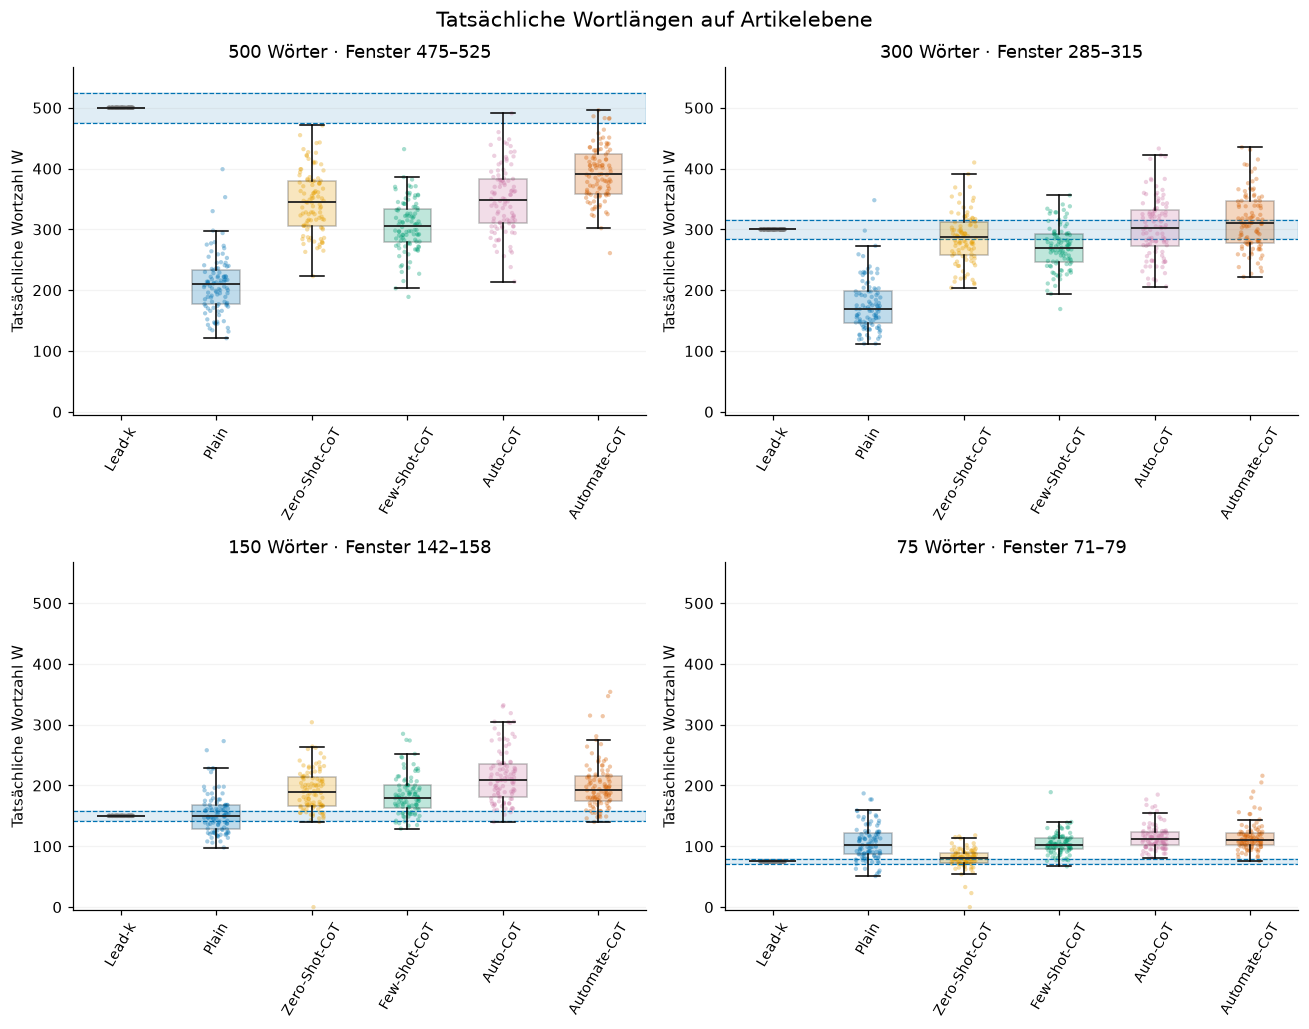

,method,stage_target_words,n_empty,n_empty_input,n_chain_failure,n_complete_sentences
0,lead_k,500,0,0,0,0
1,plain,500,0,0,0,100
2,zero_shot_cot,500,0,0,0,100
3,few_shot_cot,500,0,0,0,100
4,auto_cot,500,0,0,0,100
5,automate_cot,500,0,0,0,100
6,lead_k,300,0,0,0,0
7,plain,300,0,0,0,100
8,zero_shot_cot,300,0,0,0,99
9,few_shot_cot,300,0,0,0,100


In [16]:
fig,axes = plt.subplots(2,2,figsize=(12,9.5))
jitter = np.random.default_rng(SEED).uniform(-.13,.13,size=len(IDS))
for ax,stage in zip(axes.flat,STAGES):
    U,O = WINDOWS[stage]
    ax.axhspan(U,O,color="#0072B2",alpha=.12,zorder=0)
    ax.axhline(U,color="#0072B2",ls="--",lw=.8)
    ax.axhline(O,color="#0072B2",ls="--",lw=.8)
    arrays = [article[(article.method==m)&(article.stage_target_words==stage)].sort_values("article_id").W.to_numpy() for m in METHODS]
    boxes = ax.boxplot(arrays,positions=np.arange(6),patch_artist=True,widths=.5,showfliers=False,
                       medianprops={"color":"#222222","linewidth":1.2})
    for j,(method,values) in enumerate(zip(METHODS,arrays)):
        boxes["boxes"][j].set_facecolor(COLORS[method])
        boxes["boxes"][j].set_alpha(.25)
        ax.scatter(j+jitter,values,s=8,color=COLORS[method],alpha=.35,edgecolors="none")
    ax.set(title=f"{stage} Wörter · Fenster {U}–{O}",ylabel="Tatsächliche Wortzahl W",xticks=np.arange(6),
           xticklabels=[LABELS[m] for m in METHODS],ylim=(-5,WINDOWS[500][1]*1.08),
           yticks=np.arange(0,501,100))
    ax.tick_params(axis="x",labelrotation=60,labelsize=9)
    ax.grid(axis="y",alpha=.15)
fig.suptitle("Tatsächliche Wortlängen auf Artikelebene",fontsize=14)
fig.tight_layout()
savefig(fig,"A01_wortlaengen_verteilungen")
status_quality = main[["method","stage_target_words","n_empty","n_empty_input","n_chain_failure","n_complete_sentences"]]
export(status_quality,"A02_generierungsstatus_und_satzabschluss")
display(status_quality)


## 7. Deutscher Ergebnistext für Kapitel 4.3

Der folgende Entwurf wird aus den ausgeführten Tabellen erzeugt. Er beschränkt den
Haupttext auf die zwei Hauptabbildungen und eine kompakte Rangtabelle. Die vollständigen
24-Gruppen-Matrizen, Artikelwerte und Sensitivitäten bleiben in den Notebook-/CSV-Anhängen.
Die Bezeichnungen 4.3-1 / 4.3-2 sind bei Bedarf an die endgültige Abbildungszählung anzupassen.

In [17]:
lookup_main = main.set_index(["method","stage_target_words"])
lookup98 = sensitivity.set_index(["method","stage_target_words"])
paragraphs = ["# 4.3 Längeneinhaltung und längenadjustierte Faktenretention",
    "## 4.3.1 Einhaltung der Wortvorgaben",
    "Für F3 wurden die tatsächlich erzeugten Texte von 100 Artikeln, sechs Verfahren und vier rekursiven Zielstufen untersucht (2.400 Artikel-Methoden-Stufen-Zeilen). "
    "Verwendet wurde derselbe aktuelle Datenstand wie in Kapitel 4.2: vier ursprüngliche Verfahren und die neuen Plain-/Few-Shot-CoT-Ketten vom 30. September 2026. "
    "Die Regex-Wortzählung wurde gegen sämtliche gespeicherten Zähler geprüft. Die zulässigen inklusiven Fenster waren 475–525, 285–315, 142–158 und 71–79 Wörter. "
    "Abbildung 4.3-1 zeigt die Unter-/Fenster-/Überzahlen; n = 100 je Verfahren und Stufe.",
    "Lead-k hielt alle vier Fenster bei sämtlichen Artikeln ein. Für die generativen Verfahren zeigte sich dagegen ein stufenabhängiges Muster."]
for stage in STAGES:
    groups = main[(main.stage_target_words==stage)&main.method.ne("lead_k")].set_index("method").loc[METHODS[1:]]
    if stage == 500:
        finding = (f"Plain, Zero-Shot-CoT und Few-Shot-CoT trafen das Fenster bei keinem Artikel; "
                   f"Auto-CoT bei {int(groups.loc['auto_cot','n_within'])}, Automate-CoT bei {int(groups.loc['automate_cot','n_within'])}/100. "
                   "Alle Fehler waren Unterschreitungen.")
    elif stage == 300:
        cot = groups.drop(index="plain")
        finding = (f"Plain unterschritt das Fenster bei {int(groups.loc['plain','n_under'])}/100 Artikeln. "
                   f"Die CoT-Verfahren trafen es bei {int(cot.n_within.min())}–{int(cot.n_within.max())}/100 und zeigten Fehler in beiden Richtungen. "
                   f"Auto-CoT und Automate-CoT überschritten es bei {int(cot.loc['auto_cot','n_over'])} beziehungsweise {int(cot.loc['automate_cot','n_over'])}/100.")
    elif stage == 150:
        cot = groups.drop(index="plain")
        finding = (f"Die CoT-Verfahren erzeugten bei {int(cot.n_over.min())}–{int(cot.n_over.max())}/100 Artikeln Überlängen. "
                   f"Plain lag bei {int(groups.loc['plain','n_under'])} Artikeln unter, {int(groups.loc['plain','n_within'])} im und "
                   f"{int(groups.loc['plain','n_over'])} über dem Fenster.")
    else:
        others = groups.drop(index="zero_shot_cot")
        finding = (f"Zero-Shot-CoT traf das Fenster bei {int(groups.loc['zero_shot_cot','n_within'])}/100 Artikeln, "
                   f"lag jedoch bei {int(groups.loc['zero_shot_cot','n_over'])} darüber und {int(groups.loc['zero_shot_cot','n_under'])} darunter. "
                   f"Die anderen generativen Verfahren überschritten es bei {int(others.n_over.min())}–{int(others.n_over.max())}/100.")
    worst = groups.D_mean.idxmax()
    best = groups.D_mean.idxmin()
    r = groups.loc[worst]
    paragraphs.append(f"Bei {stage} Zielwörtern zeigte sich folgendes Muster: {finding} "
        f"Der mittlere normalisierte Abstand D reichte unter den generativen Verfahren von {fmt(groups.loc[best,'D_mean'],3)} "
        f"bei {LABELS[best]} bis {fmt(r.D_mean,3)} bei {LABELS[worst]} (95-%-Artikelbootstrap-Intervall "
        f"[{fmt(r.D_ci_low,3)}; {fmt(r.D_ci_high,3)}]).")
auto75,automate75 = lookup_main.loc[("auto_cot",75)],lookup_main.loc[("automate_cot",75)]
paragraphs.append(f"Die Fehlergröße ergänzt die Trefferquote: Bei 75 Wörtern lagen Auto-CoT und Automate-CoT im Mittel "
    f"bei {fmt(auto75.W_mean,1)} beziehungsweise {fmt(automate75.W_mean,1)} Wörtern und D ≈ {fmt(auto75.D_mean,2)}. "
    "Dieser D-Wert misst den Abstand jenseits der erlaubten Grenze, nicht den Abstand zum Sollwert. "
    "Zwei leere Zero-Shot-Ausgaben (bei 150 und 75 Wörtern) blieben als Unterschreitungen und Generierungsfehler enthalten; "
    "auch die fortgesetzte leere Informationskette blieb markiert.")
paragraphs.extend(["## 4.3.2 Faktenretention unter Berücksichtigung der Länge",
    "Abbildung 4.3-2 stellt die mittlere beobachtete QA-Retention R_obs = K/V dem mittleren D gegenüber. "
    "Die 24 Punkte sind Methoden-Stufen-Mittelwerte über dieselben 100 Artikel, keine artikelweise Korrelation oder Kausalwirkung der Länge. "
    "Bei 500 Wörtern dominiert Lead-k nach den Punktschätzern alle anderen Verfahren: höhere Retention und geringere D. "
    "Bei 150 Wörtern wird dagegen kein Verfahren dominiert. Die Pareto-Markierung berücksichtigt keine Unsicherheit.",
    "Für H2 wurde zusätzlich pro Artikel R_adj = (K/20)/(1+D) berechnet und anschließend gemittelt. "
    "Technisch fehlende QA-Urteile gelten beim festen Nenner K/20 als nicht erhalten. Innerhalb des Fensters entspricht R_adj daher R_zero, "
    "nicht grundsätzlich R_obs. Der Abschlag wurde in den Nenneranteil R_obs−R_zero und den Längenanteil R_zero−R_adj zerlegt. "
    "Im Hauptpanel veränderte der Nenneranteil keine Rangfolge; die beobachteten Wechsel entstanden erst durch D."])
paragraphs.append(f"Der feste QA-Nenner verringerte den Gruppenmittelwert um höchstens "
    f"{fmt(100*main.qa_denominator_gap_mean.max())} Prozentpunkte; der reine Längenabschlag erreichte dagegen bis zu "
    f"{fmt(100*main.length_penalty_mean.max())} Prozentpunkte. Beide Größen werden getrennt im Anhang ausgewiesen.")
for stage in STAGES:
    sub = main[main.stage_target_words.eq(stage)].sort_values("rank_R_adj",kind="stable")
    if stage == 500:
        delta,lo,hi = oriented_pair(pairs,stage,"zero_shot_cot","auto_cot")
        paragraphs.append(f"Bei 500 Wörtern blieb die Rangfolge unverändert. Lead-k erreichte den höchsten adjustierten Mittelwert "
            f"({fmt(100*lookup_main.loc[('lead_k',500),'R_adj_mean'])} %). Zero-Shot-CoT und Auto-CoT lagen nach Adjustierung nur "
            f"{fmt(delta)} Prozentpunkte auseinander (gepaartes 95-%-Intervall [{fmt(lo)}; {fmt(hi)}]).")
    else:
        leaders = ", ".join(f"{LABELS[r.method]} {fmt(100*r.R_adj_mean)} %" for r in sub.head(4 if stage==150 else 3).itertuples())
        first,second = sub.method.iloc[:2]
        delta,lo,hi = oriented_pair(pairs,stage,first,second)
        change_note = ("Zero-Shot-CoT überholte Auto-CoT, Lead-k überholte Plain." if stage==300 else
                       "Zero-Shot-CoT stieg von Rang 3 auf 1; Auto-CoT fiel von 1 auf 4." if stage==150 else
                       "Zero-Shot-CoT stieg von Rang 5 auf 2; Auto-CoT blieb auf Rang 1.")
        paragraphs.append(f"Bei {stage} Wörtern änderte die Adjustierung die Rangfolge. {change_note} "
            f"Die höchsten adjustierten Mittelwerte waren {leaders}. Der Abstand der beiden führenden Verfahren betrug "
            f"{fmt(delta)} Prozentpunkte [{fmt(lo)}; {fmt(hi)}].")
paragraphs.append(f"Damit unterschied sich die Rangfolge nach R_adj auf drei von vier Stufen von der Rangfolge nach R_obs "
    f"({int(main.rank_changed_H2.sum())} von 24 Rangpositionen; Tabelle 4.3-1). Dies entspricht H2 als deskriptivem Rangvergleich; "
    "eine nachträgliche formale Testentscheidung wird daraus nicht abgeleitet. Die knappen Spitzenabstände und ihre Intervalle belegen "
    "keinen klaren Leistungsvorteil. Artikelbootstrap-Ranghäufigkeiten stehen im Anhang.")
delta,lo,hi = oriented_pair(pairs98,75,"zero_shot_cot","auto_cot")
paragraphs.append(f"Nach gemeinsamem Ausschluss der beiden Fehlerartikel (n = 98 für alle Verfahren) blieben die zentralen Längenmuster "
    "und Rangänderungen auf drei Stufen bestehen. Die adjustierte Spitzenposition bei 75 Wörtern wechselte jedoch von Auto-CoT zu Zero-Shot-CoT "
    f"({fmt(100*lookup98.loc[('zero_shot_cot',75),'R_adj_mean'])} % gegenüber {fmt(100*lookup98.loc[('auto_cot',75),'R_adj_mean'])} %; "
    f"gepaarte Differenz {fmt(delta)} pp [{fmt(lo)}; {fmt(hi)}]). Bei 300 Wörtern entstand die Vertauschung von Auto-CoT und Zero-Shot-CoT "
    "bereits durch den festen QA-Nenner; Lead-k und Plain waren auf dieser Zwischenkennzahl exakt gleichrangig. "
    "Die Herkunft von Rangwechseln ist somit teilweise populationsabhängig.")
paragraphs.append("Die Intervalle beruhen auf 10.000 gepaarten Artikelbootstrap-Ziehungen mit Seed 32 und sind punktweise, "
    "nicht für Mehrfachvergleiche korrigiert. Die adjustierte Sekundärkennzahl beschreibt einen festgelegten Trade-off und ersetzt nicht "
    "die getrennte Beurteilung von QA-Retention und Längeneinhaltung. Vollständige Verteilungen und Abschlagskomponenten stehen im Anhang.")
chapter = "\n\n".join(paragraphs)
table_lines = ["| Verfahren | 500 Wörter | 300 Wörter | 150 Wörter | 75 Wörter |", "|---|---:|---:|---:|---:|"]
for label,row in rank_display.iterrows():
    table_lines.append("| " + label + " | " + " | ".join(row.tolist()) + " |")
chapter += "\n\n**Tabelle 4.3-1.** Rang nach R_obs → Rang nach R_adj; * markiert Wechsel. Ungerundete Artikelmittelwerte, n = 100.\n\n" + "\n".join(table_lines)
chapter += "\n\n**Abbildung 4.3-1.** Einhaltung der inklusiven Wortfenster: Anzahl unter, im und über dem Fenster, n = 100 je Verfahren und Stufe.\n"
chapter += "\n**Abbildung 4.3-2.** Mittlere beobachtete QA-Retention und mittlere normalisierte Fensterabweichung; 24 Methoden-Stufen-Mittelwerte, jeweils n = 100. Ringe markieren nichtdominierte Punktschätzer ohne Unsicherheit.\n"
(OUT/"Kapitel_4_3_Laengeneinhaltung.md").write_text(chapter,encoding="utf-8")
display(Markdown(chapter))


# 4.3 Längeneinhaltung und längenadjustierte Faktenretention

## 4.3.1 Einhaltung der Wortvorgaben

Für F3 wurden die tatsächlich erzeugten Texte von 100 Artikeln, sechs Verfahren und vier rekursiven Zielstufen untersucht (2.400 Artikel-Methoden-Stufen-Zeilen). Verwendet wurde derselbe aktuelle Datenstand wie in Kapitel 4.2: vier ursprüngliche Verfahren und die neuen Plain-/Few-Shot-CoT-Ketten vom 30. September 2026. Die Regex-Wortzählung wurde gegen sämtliche gespeicherten Zähler geprüft. Die zulässigen inklusiven Fenster waren 475–525, 285–315, 142–158 und 71–79 Wörter. Abbildung 4.3-1 zeigt die Unter-/Fenster-/Überzahlen; n = 100 je Verfahren und Stufe.

Lead-k hielt alle vier Fenster bei sämtlichen Artikeln ein. Für die generativen Verfahren zeigte sich dagegen ein stufenabhängiges Muster.

Bei 500 Zielwörtern zeigte sich folgendes Muster: Plain, Zero-Shot-CoT und Few-Shot-CoT trafen das Fenster bei keinem Artikel; Auto-CoT bei 1, Automate-CoT bei 5/100. Alle Fehler waren Unterschreitungen. Der mittlere normalisierte Abstand D reichte unter den generativen Verfahren von 0,166 bei Automate-CoT bis 0,531 bei Plain (95-%-Artikelbootstrap-Intervall [0,513; 0,549]).

Bei 300 Zielwörtern zeigte sich folgendes Muster: Plain unterschritt das Fenster bei 98/100 Artikeln. Die CoT-Verfahren trafen es bei 19–29/100 und zeigten Fehler in beiden Richtungen. Auto-CoT und Automate-CoT überschritten es bei 41 beziehungsweise 44/100. Der mittlere normalisierte Abstand D reichte unter den generativen Verfahren von 0,070 bei Zero-Shot-CoT bis 0,368 bei Plain (95-%-Artikelbootstrap-Intervall [0,342; 0,392]).

Bei 150 Zielwörtern zeigte sich folgendes Muster: Die CoT-Verfahren erzeugten bei 78–97/100 Artikeln Überlängen. Plain lag bei 39 Artikeln unter, 22 im und 39 über dem Fenster. Der mittlere normalisierte Abstand D reichte unter den generativen Verfahren von 0,111 bei Plain bis 0,384 bei Auto-CoT (95-%-Artikelbootstrap-Intervall [0,329; 0,442]).

Bei 75 Zielwörtern zeigte sich folgendes Muster: Zero-Shot-CoT traf das Fenster bei 33/100 Artikeln, lag jedoch bei 53 darüber und 14 darunter. Die anderen generativen Verfahren überschritten es bei 86–100/100. Der mittlere normalisierte Abstand D reichte unter den generativen Verfahren von 0,115 bei Zero-Shot-CoT bis 0,482 bei Automate-CoT (95-%-Artikelbootstrap-Intervall [0,423; 0,548]).

Die Fehlergröße ergänzt die Trefferquote: Bei 75 Wörtern lagen Auto-CoT und Automate-CoT im Mittel bei 115,1 beziehungsweise 115,2 Wörtern und D ≈ 0,48. Dieser D-Wert misst den Abstand jenseits der erlaubten Grenze, nicht den Abstand zum Sollwert. Zwei leere Zero-Shot-Ausgaben (bei 150 und 75 Wörtern) blieben als Unterschreitungen und Generierungsfehler enthalten; auch die fortgesetzte leere Informationskette blieb markiert.

## 4.3.2 Faktenretention unter Berücksichtigung der Länge

Abbildung 4.3-2 stellt die mittlere beobachtete QA-Retention R_obs = K/V dem mittleren D gegenüber. Die 24 Punkte sind Methoden-Stufen-Mittelwerte über dieselben 100 Artikel, keine artikelweise Korrelation oder Kausalwirkung der Länge. Bei 500 Wörtern dominiert Lead-k nach den Punktschätzern alle anderen Verfahren: höhere Retention und geringere D. Bei 150 Wörtern wird dagegen kein Verfahren dominiert. Die Pareto-Markierung berücksichtigt keine Unsicherheit.

Für H2 wurde zusätzlich pro Artikel R_adj = (K/20)/(1+D) berechnet und anschließend gemittelt. Technisch fehlende QA-Urteile gelten beim festen Nenner K/20 als nicht erhalten. Innerhalb des Fensters entspricht R_adj daher R_zero, nicht grundsätzlich R_obs. Der Abschlag wurde in den Nenneranteil R_obs−R_zero und den Längenanteil R_zero−R_adj zerlegt. Im Hauptpanel veränderte der Nenneranteil keine Rangfolge; die beobachteten Wechsel entstanden erst durch D.

Der feste QA-Nenner verringerte den Gruppenmittelwert um höchstens 0,57 Prozentpunkte; der reine Längenabschlag erreichte dagegen bis zu 18,45 Prozentpunkte. Beide Größen werden getrennt im Anhang ausgewiesen.

Bei 500 Wörtern blieb die Rangfolge unverändert. Lead-k erreichte den höchsten adjustierten Mittelwert (75,40 %). Zero-Shot-CoT und Auto-CoT lagen nach Adjustierung nur 0,08 Prozentpunkte auseinander (gepaartes 95-%-Intervall [-1,95; 2,08]).

Bei 300 Wörtern änderte die Adjustierung die Rangfolge. Zero-Shot-CoT überholte Auto-CoT, Lead-k überholte Plain. Die höchsten adjustierten Mittelwerte waren Automate-CoT 63,86 %, Zero-Shot-CoT 63,62 %, Auto-CoT 62,77 %. Der Abstand der beiden führenden Verfahren betrug 0,24 Prozentpunkte [-2,18; 2,62].

Bei 150 Wörtern änderte die Adjustierung die Rangfolge. Zero-Shot-CoT stieg von Rang 3 auf 1; Auto-CoT fiel von 1 auf 4. Die höchsten adjustierten Mittelwerte waren Zero-Shot-CoT 44,06 %, Few-Shot-CoT 43,07 %, Automate-CoT 42,88 %, Auto-CoT 42,54 %. Der Abstand der beiden führenden Verfahren betrug 0,99 Prozentpunkte [-1,50; 3,43].

Bei 75 Wörtern änderte die Adjustierung die Rangfolge. Zero-Shot-CoT stieg von Rang 5 auf 2; Auto-CoT blieb auf Rang 1. Die höchsten adjustierten Mittelwerte waren Auto-CoT 26,88 %, Zero-Shot-CoT 26,34 %, Few-Shot-CoT 26,13 %. Der Abstand der beiden führenden Verfahren betrug 0,54 Prozentpunkte [-1,63; 2,77].

Damit unterschied sich die Rangfolge nach R_adj auf drei von vier Stufen von der Rangfolge nach R_obs (11 von 24 Rangpositionen; Tabelle 4.3-1). Dies entspricht H2 als deskriptivem Rangvergleich; eine nachträgliche formale Testentscheidung wird daraus nicht abgeleitet. Die knappen Spitzenabstände und ihre Intervalle belegen keinen klaren Leistungsvorteil. Artikelbootstrap-Ranghäufigkeiten stehen im Anhang.

Nach gemeinsamem Ausschluss der beiden Fehlerartikel (n = 98 für alle Verfahren) blieben die zentralen Längenmuster und Rangänderungen auf drei Stufen bestehen. Die adjustierte Spitzenposition bei 75 Wörtern wechselte jedoch von Auto-CoT zu Zero-Shot-CoT (26,87 % gegenüber 26,80 %; gepaarte Differenz 0,08 pp [-1,94; 2,05]). Bei 300 Wörtern entstand die Vertauschung von Auto-CoT und Zero-Shot-CoT bereits durch den festen QA-Nenner; Lead-k und Plain waren auf dieser Zwischenkennzahl exakt gleichrangig. Die Herkunft von Rangwechseln ist somit teilweise populationsabhängig.

Die Intervalle beruhen auf 10.000 gepaarten Artikelbootstrap-Ziehungen mit Seed 32 und sind punktweise, nicht für Mehrfachvergleiche korrigiert. Die adjustierte Sekundärkennzahl beschreibt einen festgelegten Trade-off und ersetzt nicht die getrennte Beurteilung von QA-Retention und Längeneinhaltung. Vollständige Verteilungen und Abschlagskomponenten stehen im Anhang.

**Tabelle 4.3-1.** Rang nach R_obs → Rang nach R_adj; * markiert Wechsel. Ungerundete Artikelmittelwerte, n = 100.

| Verfahren | 500 Wörter | 300 Wörter | 150 Wörter | 75 Wörter |
|---|---:|---:|---:|---:|
| Lead-k | 1 → 1 | 6 → 5 * | 6 → 6 | 6 → 6 |
| Plain | 6 → 6 | 5 → 6 * | 5 → 5 | 4 → 5 * |
| Zero-Shot-CoT | 3 → 3 | 3 → 2 * | 3 → 1 * | 5 → 2 * |
| Few-Shot-CoT | 5 → 5 | 4 → 4 | 4 → 2 * | 3 → 3 |
| Auto-CoT | 4 → 4 | 2 → 3 * | 1 → 4 * | 1 → 1 |
| Automate-CoT | 2 → 2 | 1 → 1 | 2 → 3 * | 2 → 4 * |

**Abbildung 4.3-1.** Einhaltung der inklusiven Wortfenster: Anzahl unter, im und über dem Fenster, n = 100 je Verfahren und Stufe.

**Abbildung 4.3-2.** Mittlere beobachtete QA-Retention und mittlere normalisierte Fensterabweichung; 24 Methoden-Stufen-Mittelwerte, jeweils n = 100. Ringe markieren nichtdominierte Punktschätzer ohne Unsicherheit.


## 8. Export und Prüfung

Alle Kennzahlen in CSV sind ungerundet. R-Werte sind Anteile (0–1), die paarweisen
R-Differenzen sind Prozentpunkte, D-Werte dimensionslos. Die Hauptabbildungen und
die Anhangsgrafik werden als PNG, SVG und PDF gespeichert. Der separate Exporter
erstellt eine HTML-Leseversion und ein portables ZIP-Paket mit Quellen und Anleitung.

Das Notebook enthält keinen einfachen Test über 2.400 unabhängige Zeilen und keine
Regression über sechs Methodenpunkte. Alle Unsicherheitsberechnungen verwenden
Artikel als Bootstrap-Einheit. Exportierte Satzabschlussdaten bleiben eine Diagnose.

In [18]:
execution_manifest = {
    "version": VERSION, "seed": SEED, "bootstrap_samples": B, "bootstrap_unit": "article",
    "interval": "pointwise percentile 95%; paired article indices across methods and stages",
    "n_articles_main": len(IDS), "n_analysis_rows": len(article), "n_qa_positions": len(qa),
    "n_valid_qa": int(qa.analysis_eligible.sum()), "n_missing_qa": int((~qa.analysis_eligible).sum()),
    "n_empty_outputs": int(article.empty_output.sum()), "n_chain_failure_positions": int(article.chain_failure.sum()),
    "excluded_article_ids_sensitivity": failed_ids, "n_articles_sensitivity": sensitivity_article.article_id.nunique(),
    "word_count_implementation": r"\b\w+\b", "word_count_flags": int(re.UNICODE),
    "inclusive_windows": {str(t): list(w) for t,w in WINDOWS.items()},
    "D": "(max(U-W,0)+max(W-O,0))/T",
    "R_obs": "K/V", "R_zero": "K/20", "R_adj": "(K/20)/(1+D), calculated per article before averaging",
    "ranking": "unrounded exact rational point means; competition ranking for exact ties",
    "H2": "descriptive R_obs vs R_adj ranks; no post-hoc formal test",
    "sensitivity_difference": "75-word adjusted leader changes; 300-word denominator changes order and creates exact tie",
    "source_hashes": source_hashes, "software": {"python": platform.python_version(), **software},
    "validation": {"word_counters_checked": 2400, "stored_D_values_checked": 1600, "qa_labels_checked": 48000, "chapter_4_2_matched": True,
                   "all_24_status_sums_main": 100, "all_24_status_sums_sensitivity": 98}}
(OUT/"execution_manifest.json").write_text(json.dumps(execution_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
display(Markdown("**Alle Schlüssel-, Versions-, Wortzähl-, Status-, QA-, Formel- und Abgleichprüfungen erfolgreich.**"))
files = pd.DataFrame([{"Datei": relative_path(p, BASE), "Bytes": p.stat().st_size}
                      for folder in [OUT,FIG] for p in sorted(folder.iterdir()) if p.is_file()])
display(files)


**Alle Schlüssel-, Versions-, Wortzähl-, Status-, QA-, Formel- und Abgleichprüfungen erfolgreich.**

,Datei,Bytes
0,../../results/notebooks/tables/04_laenge_und_a...,652
1,../../results/notebooks/tables/04_laenge_und_a...,7557
2,../../results/notebooks/tables/04_laenge_und_a...,202
3,../../results/notebooks/tables/04_laenge_und_a...,819410
4,../../results/notebooks/tables/04_laenge_und_a...,803031
...,...,...
35,../../results/notebooks/figures/04_laenge_und_...,400216
36,../../results/notebooks/figures/04_laenge_und_...,156661
37,../../results/notebooks/figures/04_laenge_und_...,34416
38,../../results/notebooks/figures/04_laenge_und_...,213984


## 9. Grafikvarianten zur längenadjustierten Retention

Die folgenden drei Darstellungen dienen dem direkten Vergleich möglicher Grafiken
für Kapitel 4.3. Alle verwenden **dieselben 24 Gruppenmittelwerte des 100-Artikel-Hauptpanels**.
Die längenadjustierte Retention wird weiterhin zuerst pro Artikel berechnet und
danach gemittelt. Werte auf der Prozent-Skala entsprechen 100 × mean(R_adj);
es handelt sich um die adjustierte Sekundärkennzahl.

Varianten 1 und 2 zeigen die vier Wortstufen im **2×2-Raster**. Methodenreihenfolge
und Methodenfarben bleiben gleich. Die Heatmap stellt alle 24 Mittelwerte kompakt dar.

### Variante 1: Punktdiagramm mit 95-%-Intervallen

**Frage:** Wie hoch ist die längenadjustierte Retention je Verfahren und Stufe?

Der Punkt zeigt mean(R_adj), die horizontale Linie das punktweise
95-%-Artikelbootstrap-Intervall (10.000 Ziehungen, Seed 32). Die Werte rechts
sind die Mittelwerte auf der Prozent-Skala. Die x-Skala ist in allen Panels gleich.
Die feste Methodenreihenfolge erleichtert den Vergleich zwischen den Stufen.

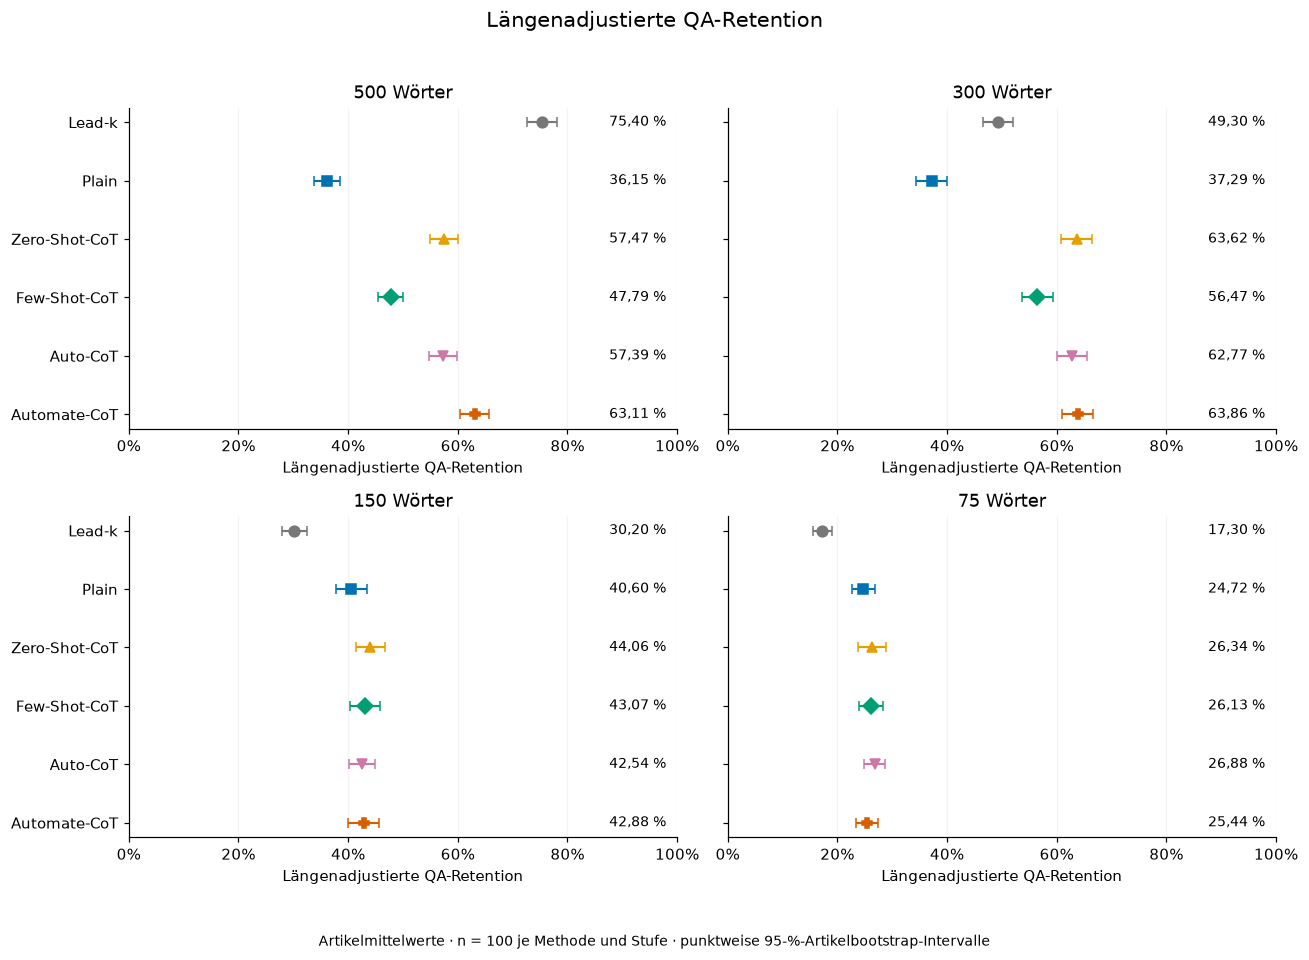

In [19]:
fig,axes = plt.subplots(2,2,figsize=(12,8.8),sharex=True,sharey=True)
y = np.arange(len(METHODS))
for ax,stage in zip(axes.flat,STAGES):
    sub = main[main.stage_target_words.eq(stage)].set_index("method").loc[METHODS]
    for i,method in enumerate(METHODS):
        row = sub.loc[method]
        mean,low,high = 100*row.R_adj_mean,100*row.R_adj_ci_low,100*row.R_adj_ci_high
        ax.errorbar(mean,i,xerr=[[mean-low],[high-mean]],fmt=MARKERS[method],
                    color=COLORS[method],capsize=3,markersize=7,elinewidth=1.4,zorder=3)
        ax.text(98,i,f"{fmt(mean)} %",ha="right",va="center",fontsize=9)
    ax.set(title=f"{stage} Wörter",xlim=(0,100),xticks=[0,20,40,60,80,100],
           yticks=y,yticklabels=[LABELS[m] for m in METHODS],
           xlabel="Längenadjustierte QA-Retention")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100,decimals=0))
    ax.tick_params(axis="x",labelbottom=True)
    ax.set_axisbelow(True)
    ax.grid(axis="x",alpha=.15)
axes[0,0].invert_yaxis()
fig.suptitle("Längenadjustierte QA-Retention",fontsize=14)
fig.text(.5,.014,"Artikelmittelwerte · n = 100 je Methode und Stufe · punktweise 95-%-Artikelbootstrap-Intervalle",ha="center",fontsize=9)
fig.tight_layout(rect=(0,.06,1,.96))
savefig(fig,"V01_adjustierte_retention_punktdiagramm")


### Variante 2: Verbundene Punkte für den Längenabschlag

**Frage:** Wie stark fällt die Kennzahl durch den Längenabschlag?

Offene Punkte zeigen mean(R_zero), gefüllte Punkte mean(R_adj). Die Verbindung
zeigt die mittlere Differenz R_zero − R_adj; rechts steht der Abschlag in
Prozentpunkten. Der kleinere adjustierte Wert steht links neben dem gefüllten Punkt,
der größere Ausgangswert rechts neben dem offenen Punkt.
Bei Lead-k überlagern sich beide Punkte, weil D = 0 ist.

Als Ausgangspunkt dient bewusst **R_zero = K/20**, damit hier nur der Längenabschlag
gezeigt wird. Die zusätzliche Differenz von R_obs zu R_zero durch technisch fehlende
QA-Urteile wird in dieser Grafik nicht als Längeneffekt dargestellt.
Diese Variante zeigt Mittelwerte; die adjustierten Intervalle stehen in Variante 1.

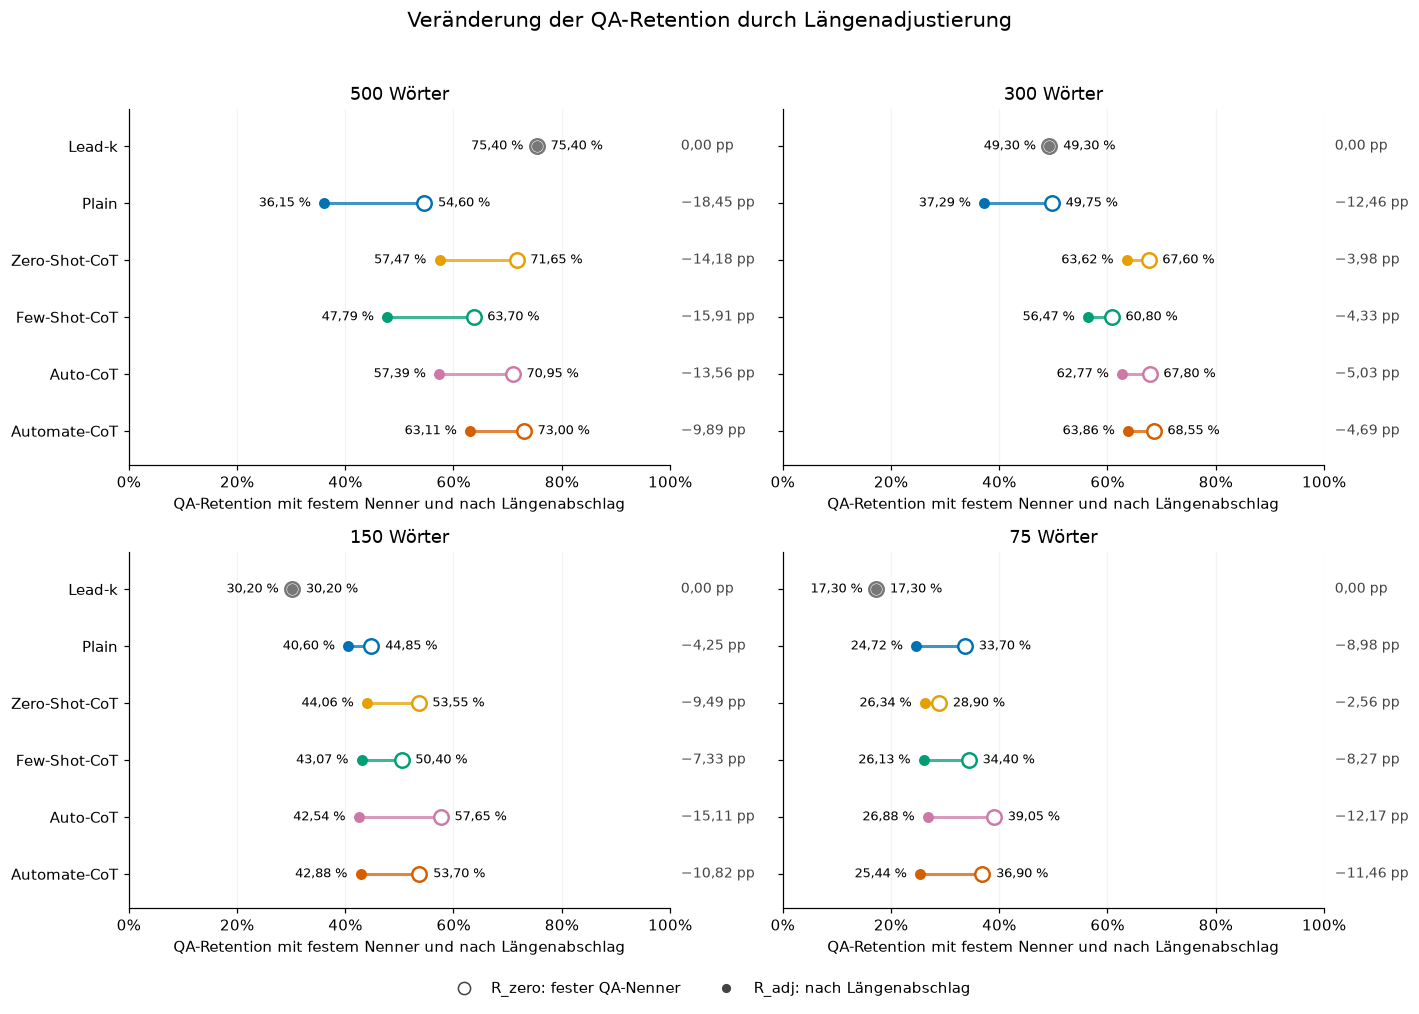

In [20]:
from matplotlib.lines import Line2D

fig,axes = plt.subplots(2,2,figsize=(13,9.5),sharex=True,sharey=True)
y = np.arange(len(METHODS))
for ax,stage in zip(axes.flat,STAGES):
    sub = main[main.stage_target_words.eq(stage)].set_index("method").loc[METHODS]
    for i,method in enumerate(METHODS):
        row = sub.loc[method]
        before,after = 100*row.R_zero_mean,100*row.R_adj_mean
        assert before >= after
        ax.plot([after,before],[i,i],color=COLORS[method],lw=2,alpha=.75,zorder=2)
        ax.scatter(before,i,s=90,facecolors="white",edgecolors=COLORS[method],linewidths=1.6,zorder=3)
        ax.scatter(after,i,s=38,color=COLORS[method],zorder=4)
        ax.annotate(f"{fmt(after)} %",xy=(after,i),xytext=(-9,0),textcoords="offset points",
                    ha="right",va="center",fontsize=8.5)
        ax.annotate(f"{fmt(before)} %",xy=(before,i),xytext=(9,0),textcoords="offset points",
                    ha="left",va="center",fontsize=8.5)
        penalty = before-after
        label = f"−{fmt(penalty)} pp" if penalty > 0 else "0,00 pp"
        ax.text(1.02,i,label,transform=ax.get_yaxis_transform(),ha="left",va="center",fontsize=9,color="#444444")
    ax.set(title=f"{stage} Wörter",xlim=(0,100),ylim=(-.65,len(METHODS)-.4),
           xticks=[0,20,40,60,80,100],yticks=y,yticklabels=[LABELS[m] for m in METHODS],
           xlabel="QA-Retention mit festem Nenner und nach Längenabschlag")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100,decimals=0))
    ax.tick_params(axis="x",labelbottom=True)
    ax.set_axisbelow(True)
    ax.grid(axis="x",alpha=.15)
axes[0,0].invert_yaxis()
handles = [Line2D([],[],marker="o",ls="none",mfc="white",mec="#444444",ms=8,label="R_zero: fester QA-Nenner"),
           Line2D([],[],marker="o",ls="none",mfc="#444444",mec="#444444",ms=5,label="R_adj: nach Längenabschlag")]
fig.legend(handles=handles,loc="lower center",ncol=2,frameon=False,bbox_to_anchor=(.5,.023))
fig.suptitle("Veränderung der QA-Retention durch Längenadjustierung",fontsize=14)
fig.tight_layout(rect=(0,.06,1,.96))
savefig(fig,"V02_retention_verbundene_punkte")


### Variante 3: Heatmap der adjustierten Mittelwerte

**Frage:** Wie verteilen sich die adjustierten Werte über alle Verfahren und Stufen?

Zeilen sind Verfahren, Spalten sind die vier Zielwortzahlen. Jede Zelle zeigt
100 × mean(R_adj); dunkleres Blau steht für höhere adjustierte Retention.
Die Farbskala reicht einheitlich von 0 bis 100 %. Die eingetragenen Zahlen
machen auch Unterschiede zwischen ähnlich gefärbten Zellen sichtbar.
Unsicherheitsintervalle stehen in Variante 1 und den vollständigen Ergebnistabellen.

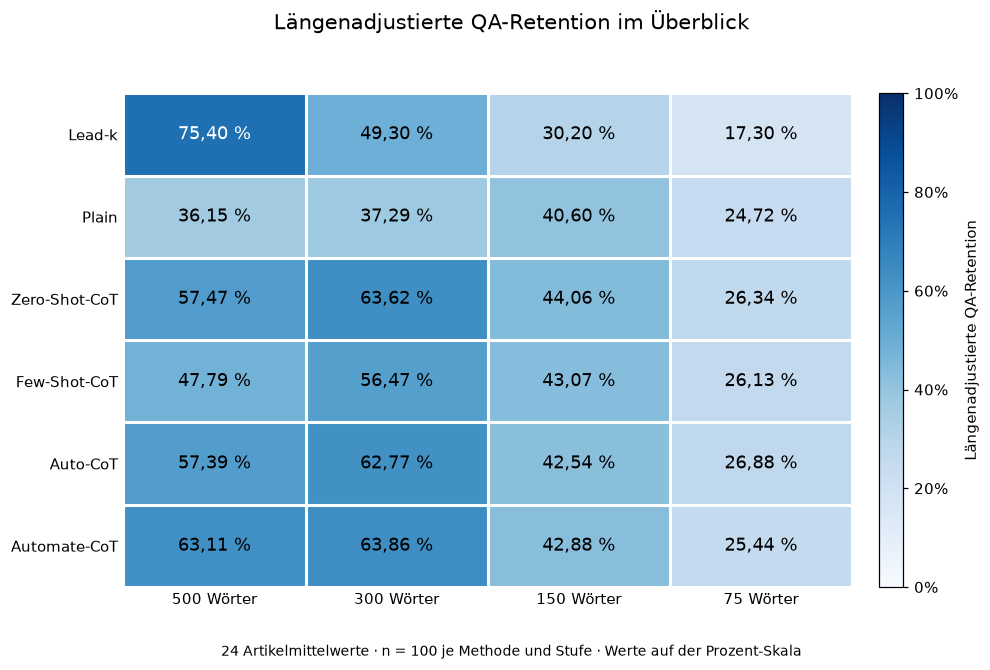

6732

In [21]:
heat_values = main.pivot(index="method",columns="stage_target_words",values="R_adj_mean").reindex(index=METHODS,columns=STAGES)
assert heat_values.shape == (6,4) and not heat_values.isna().any().any()
fig,ax = plt.subplots(figsize=(9.4,6.1))
cmap = plt.get_cmap("Blues")
image = ax.imshow(100*heat_values.to_numpy(),cmap=cmap,vmin=0,vmax=100,aspect="auto")
for i,method in enumerate(METHODS):
    for j,stage in enumerate(STAGES):
        value = 100*heat_values.loc[method,stage]
        rgb = np.array(cmap(value/100)[:3])
        linear = np.where(rgb<=.04045,rgb/12.92,((rgb+.055)/1.055)**2.4)
        luminance = float(linear @ np.array([.2126,.7152,.0722]))
        white_contrast = 1.05/(luminance+.05)
        black_contrast = (luminance+.05)/.05
        ink = "white" if white_contrast > black_contrast else "black"
        ax.text(j,i,f"{fmt(value)} %",ha="center",va="center",fontsize=12,color=ink)
ax.set(xticks=np.arange(4),xticklabels=[f"{stage} Wörter" for stage in STAGES],
       yticks=np.arange(6),yticklabels=[LABELS[m] for m in METHODS])
ax.set_xticks(np.arange(-.5,4,1),minor=True)
ax.set_yticks(np.arange(-.5,6,1),minor=True)
ax.grid(which="minor",color="white",linewidth=2)
ax.tick_params(which="both",length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
colorbar = fig.colorbar(image,ax=ax,pad=.03)
colorbar.set_label("Längenadjustierte QA-Retention")
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=100,decimals=0))
fig.suptitle("Längenadjustierte QA-Retention im Überblick",fontsize=14)
fig.text(.5,.018,"24 Artikelmittelwerte · n = 100 je Methode und Stufe · Werte auf der Prozent-Skala",ha="center",fontsize=9)
fig.tight_layout(rect=(0,.065,1,.95))
savefig(fig,"V03_adjustierte_retention_heatmap")
execution_manifest["additional_visual_variants"] = [
    "V01_adjustierte_retention_punktdiagramm", "V02_retention_verbundene_punkte", "V03_adjustierte_retention_heatmap"]
(OUT/"execution_manifest.json").write_text(json.dumps(execution_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
